# Measuring Matter Antimatter Asymmetries at the Large Hadron Collider

![](http://lhcb-public.web.cern.ch/lhcb-public/en/LHCb-outreach/multimedia/LHCbDetectorpnglight1.png)

In [2]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import CenteredNorm
import scipy.stats

import lhcb_freq as lf   # functions + settings live in lhcb_freq.py

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
# All the settings in one place (fit window, signal region, preselection cuts, n. of exponentials, limits, ...)
cfg = lf.Config(
    data_dir=Path(r"C:\\Users\\marco\\Documents\\Università\\Anno IV\\Statistics_and_Data_Analysis\\Data"),
    sim_file=Path(r"C:\\Users\\marco\\Documents\\Università\\Anno IV\\Statistics_and_Data_Analysis\\Data\\PhaseSpaceSimulation.root"),
)
cfg

Config(data_dir=WindowsPath('C:/Users/marco/Documents/Università/Anno IV/Statistics_and_Data_Analysis/Data'), data_files=('B2HHH_MagnetDown.root', 'B2HHH_MagnetUp.root'), data_tree='DecayTree', sim_file=WindowsPath('C:/Users/marco/Documents/Università/Anno IV/Statistics_and_Data_Analysis/Data/PhaseSpaceSimulation.root'), sim_tree='PhaseSpaceTree', n_products=3, m_K=493.677, m_Pi=139.57039, m_B=5279.41, prob_k_min=0.5, prob_pi_max=0.5, prob_pi_min=0.5, prob_k_max=0.5, fit_window=(5100.0, 6000.0), sig_region=(5200.0, 5350.0), n_exp=2, limits={'N_sig': (0, None), 'N_bkg': (0, None), 'A_CP': (-1.0, 1.0), 'sigma': (1.0, 100.0), 'lam': (1e-06, 1.0), 'f_bkgs': (0.0, 1.0)})

## Simulation Data

In [4]:
df_sim = lf.load_tree(cfg.sim_file, cfg.sim_tree)
print(df_sim.columns.tolist())
df_sim.head()

['B_FlightDistance', 'B_VertexChi2', 'H1_PX', 'H1_PY', 'H1_PZ', 'H1_ProbK', 'H1_ProbPi', 'H1_Charge', 'H1_IPChi2', 'H1_isMuon', 'H2_PX', 'H2_PY', 'H2_PZ', 'H2_ProbK', 'H2_ProbPi', 'H2_Charge', 'H2_IPChi2', 'H2_isMuon', 'H3_PX', 'H3_PY', 'H3_PZ', 'H3_ProbK', 'H3_ProbPi', 'H3_Charge', 'H3_IPChi2', 'H3_isMuon']


,B_FlightDistance,B_VertexChi2,H1_PX,H1_PY,H1_PZ,H1_ProbK,H1_ProbPi,H1_Charge,H1_IPChi2,H1_isMuon,...,H2_IPChi2,H2_isMuon,H3_PX,H3_PY,H3_PZ,H3_ProbK,H3_ProbPi,H3_Charge,H3_IPChi2,H3_isMuon
0,0.0,1.0,3551.84,1636.96,23904.14,1.0,0.0,-1,1.0,0,...,1.0,0,36100.40,16546.83,295600.61,1.0,0.0,-1,1.0,0
1,0.0,1.0,-2525.98,-5284.05,35822.00,1.0,0.0,1,1.0,0,...,1.0,0,-8648.32,-16617.56,98535.13,1.0,0.0,-1,1.0,0
2,0.0,1.0,-700.67,1299.73,8127.76,1.0,0.0,-1,1.0,0,...,1.0,0,-13483.34,10860.77,79787.59,1.0,0.0,1,1.0,0
3,0.0,1.0,3364.63,1397.30,222815.29,1.0,0.0,1,1.0,0,...,1.0,0,1925.16,-551.12,40420.96,1.0,0.0,1,1.0,0
4,0.0,1.0,-581.66,-1305.24,22249.59,1.0,0.0,-1,1.0,0,...,1.0,0,-2820.04,-8305.43,250130.00,1.0,0.0,-1,1.0,0


### Data exploration

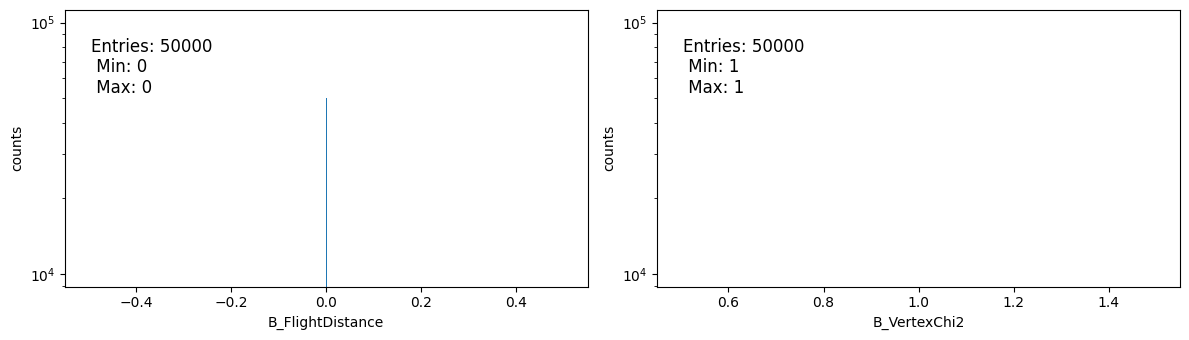

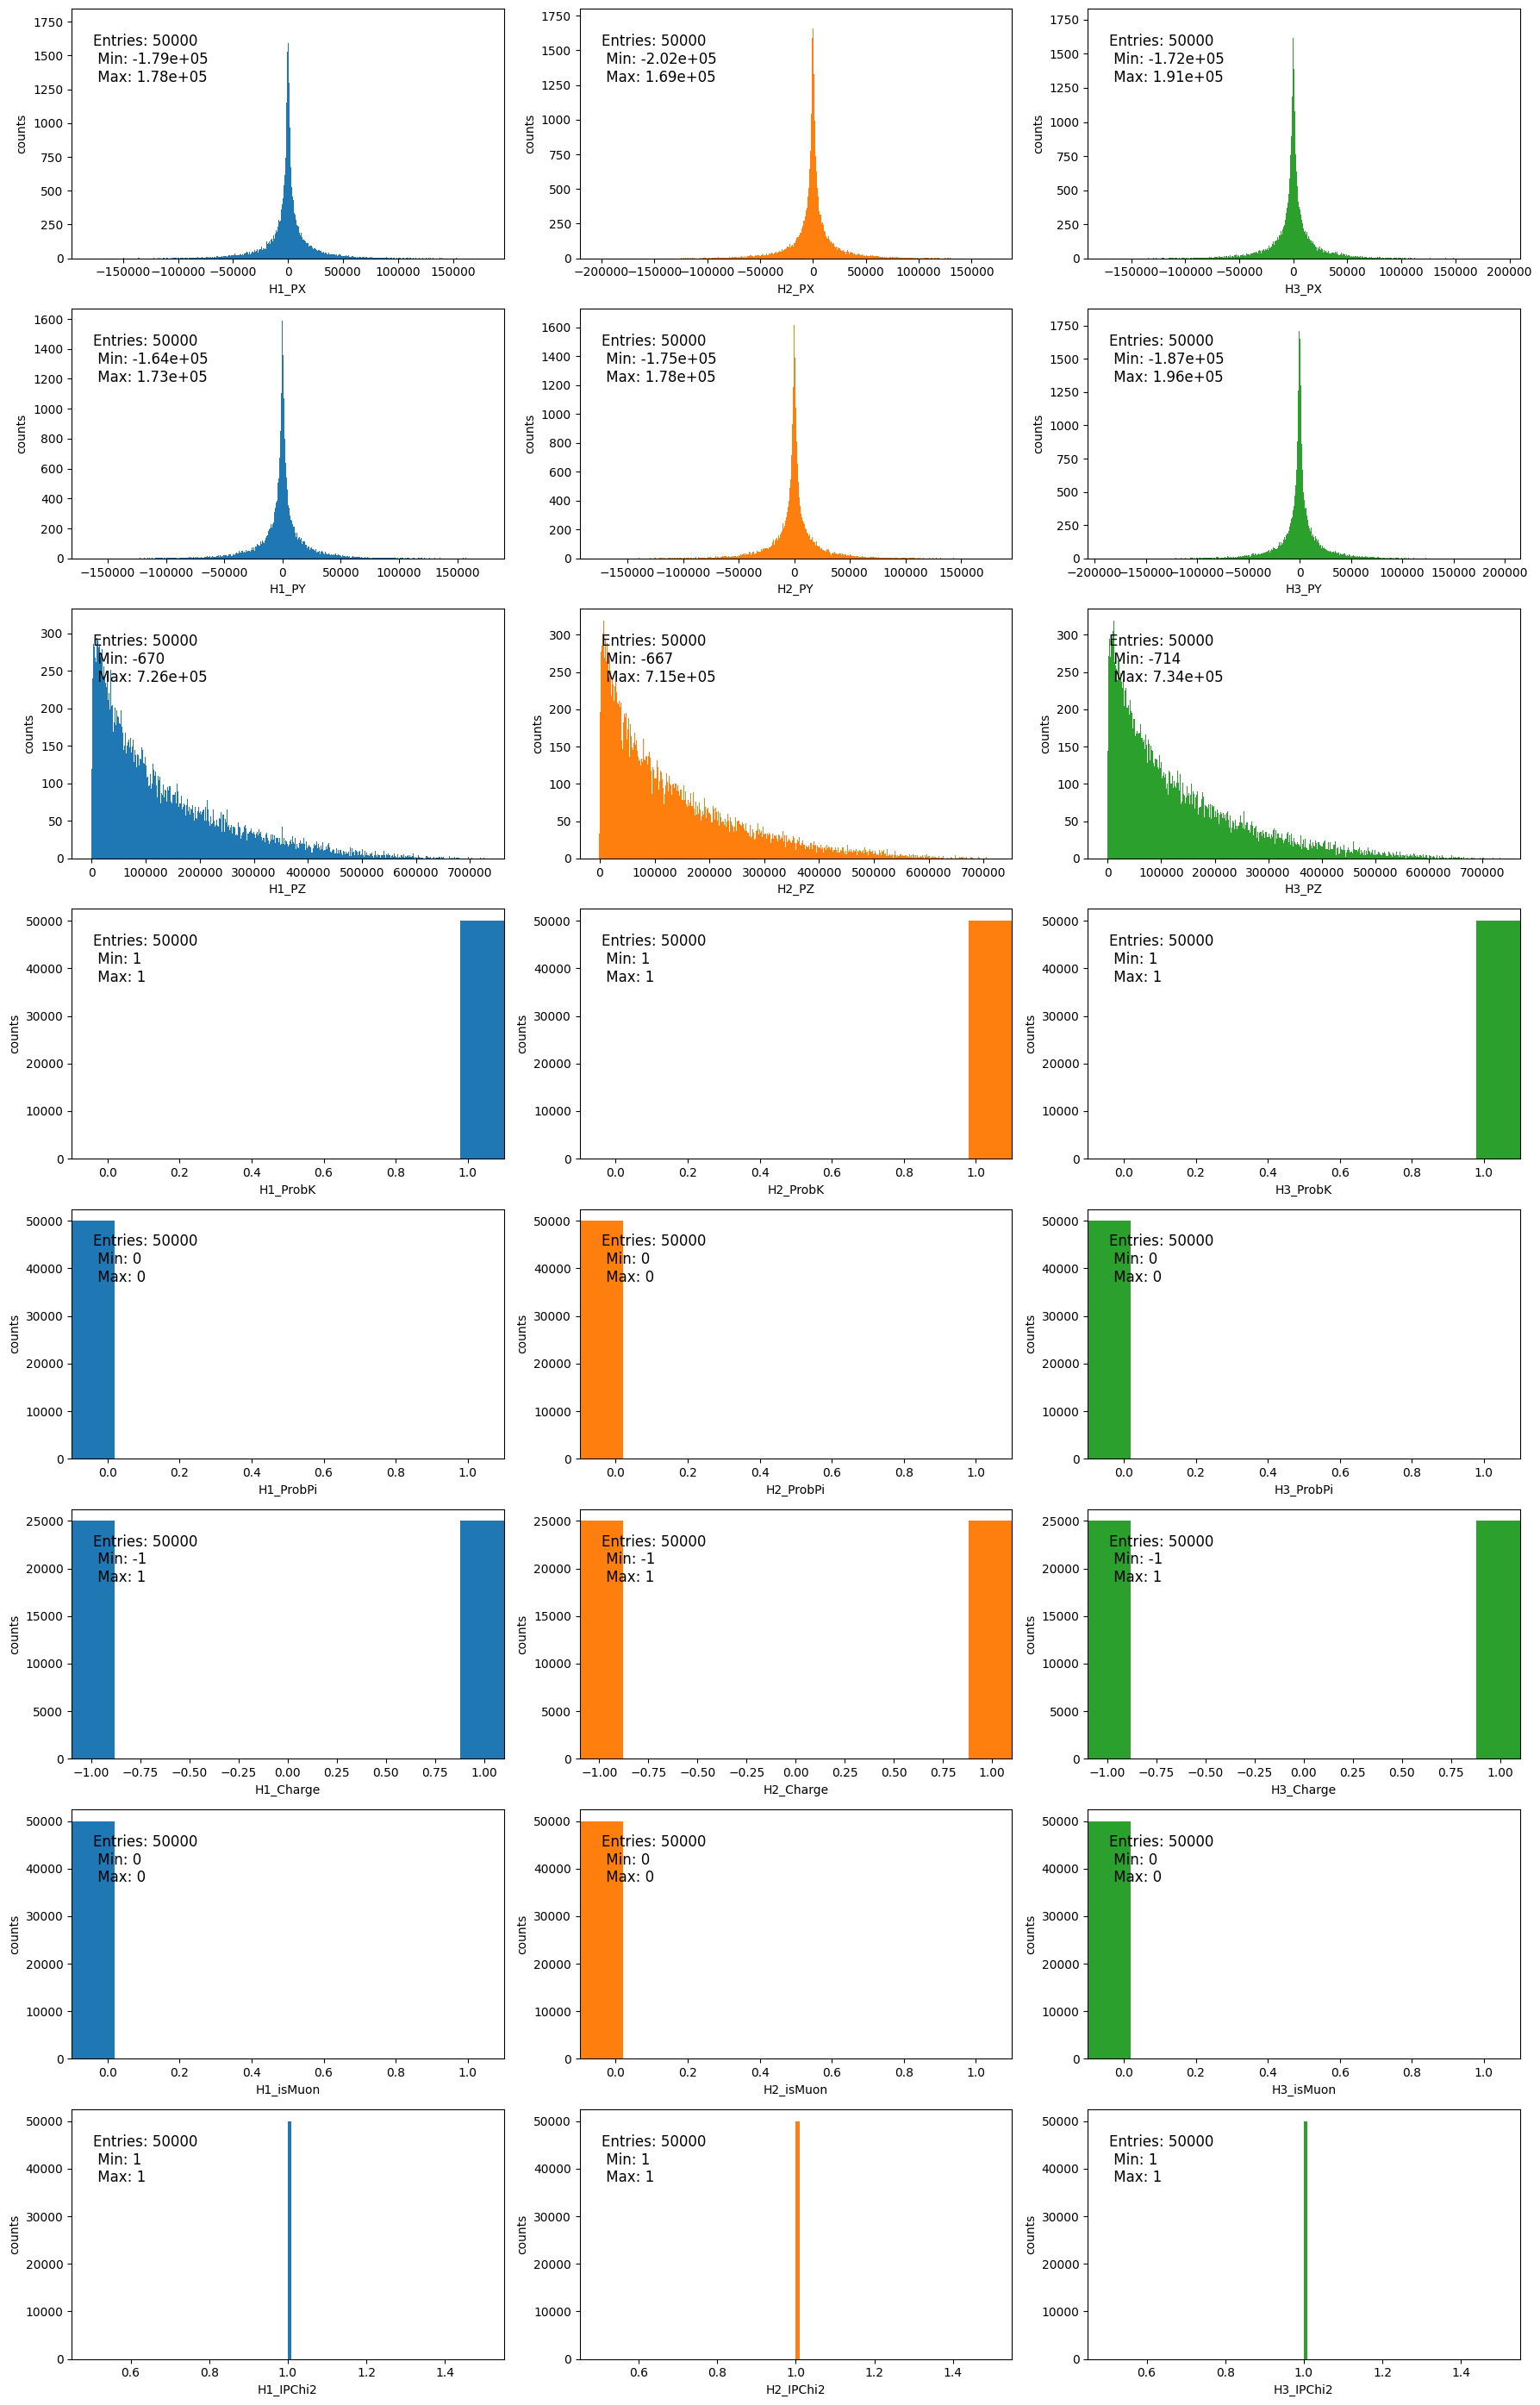

In [5]:
figs = lf.plot_all_features(df_sim, lf.GLOBAL_FEATURES, lf.PRODUCT_FEATURES + lf.EXTRA_PRODUCT_FEATURES,
                            lf.PLOT_SETTINGS["sim"], cfg.n_products)

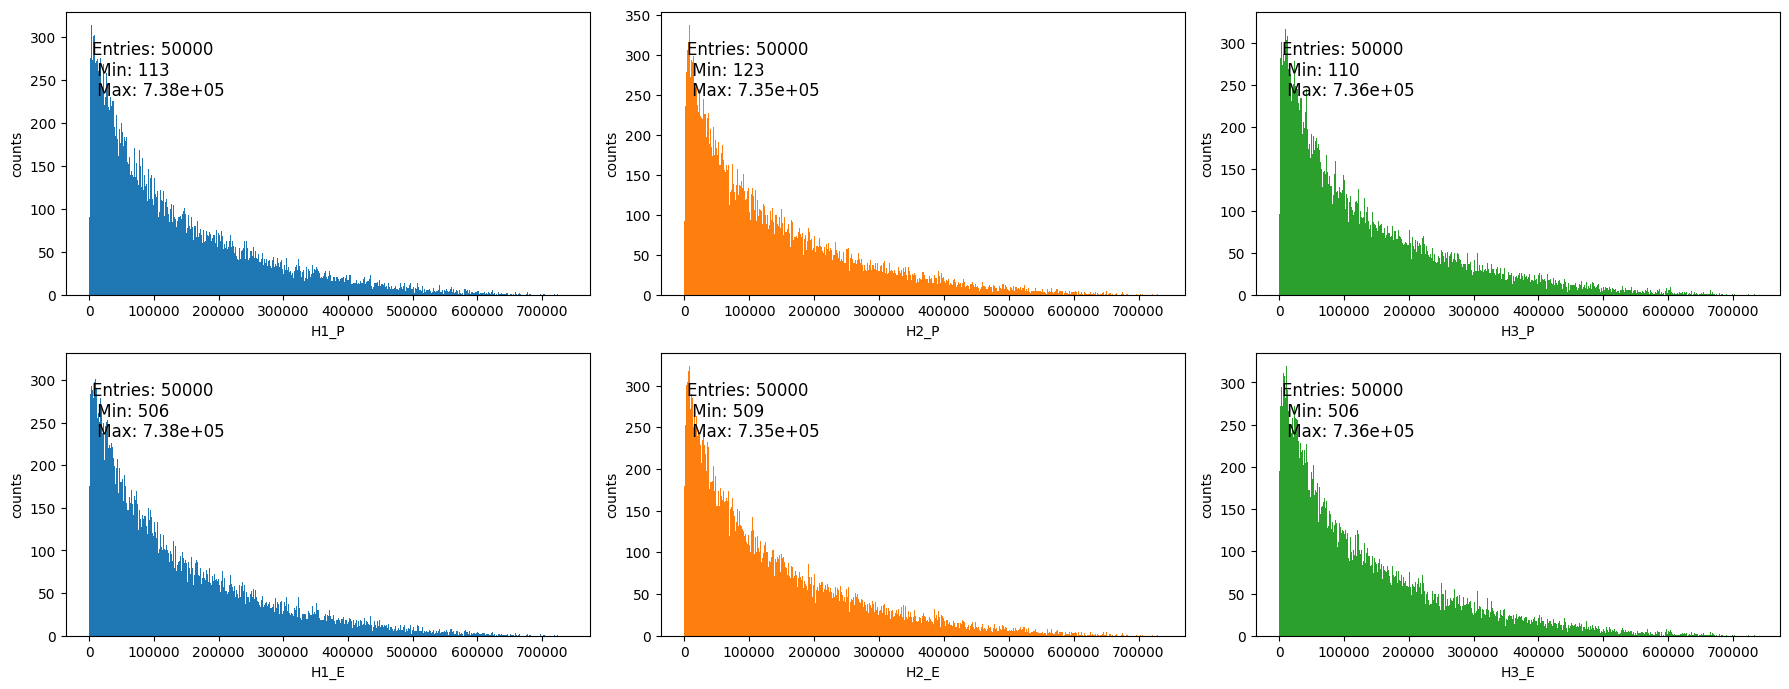

In [6]:
# New features: momentum magnitude and energy of each product
lf.add_kinematics(df_sim, cfg)
figs = lf.plot_all_features(df_sim, product_features=["P", "E"], settings=lf.PLOT_SETTINGS["sim"], n_products=cfg.n_products)

### Compute Invariant Mass

In [7]:
lf.add_B_variables(df_sim, cfg)      # adds B_Mass and B_Charge
df_sim[["B_Mass", "B_Charge"]].describe()

,B_Mass,B_Charge
count,50000.000000,50000.00000
mean,5267.883223,0.00000
std,80.964681,1.00001
min,2909.905221,-1.00000
25%,5279.241654,-1.00000
50%,5279.248254,0.00000
75%,5279.253599,1.00000
max,5279.279077,1.00000


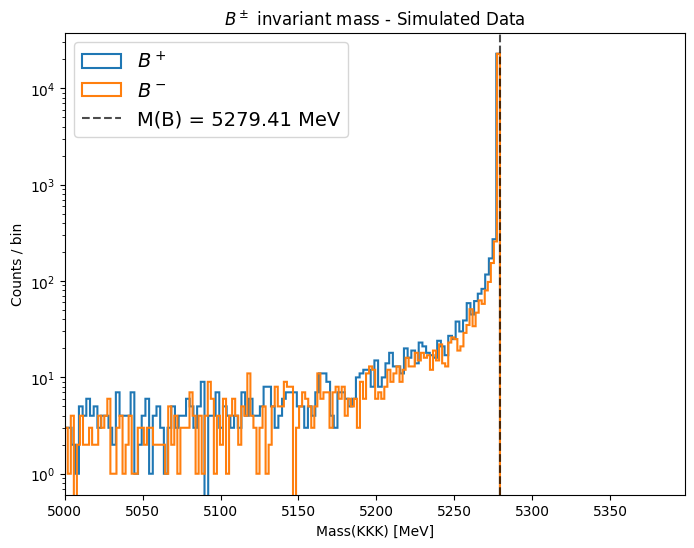

In [8]:
lf.plot_mass_by_charge(df_sim, cfg, bins=1000, logy=True, xlim=(5000, None),
                       title=r"$B^\pm$ invariant mass - Simulated Data");

max |m_vector - m_numpy| = 2.7284841053187847e-12 MeV


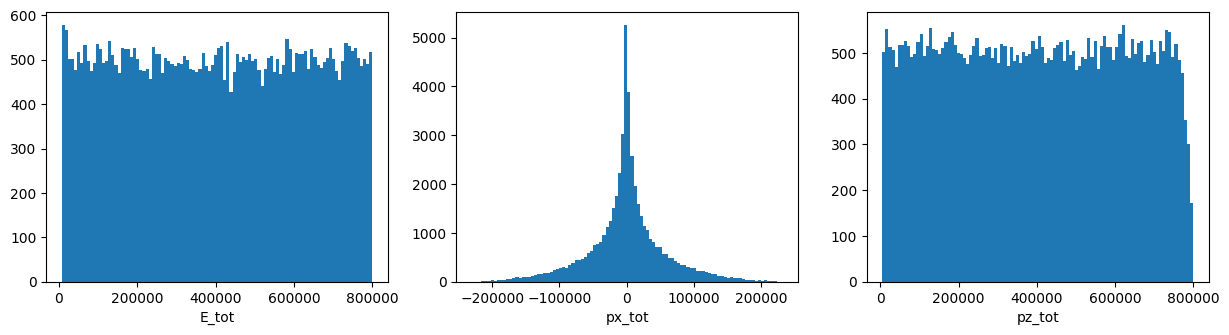

In [9]:
# Independent cross-check of the `vector` result with plain numpy (energy/momentum conservation, m^2 = E^2 - p^2)
E_tot = sum(np.sqrt(sum(df_sim[f"H{i}_{c}"]**2 for c in ("PX", "PY", "PZ")) + cfg.m_K**2) for i in cfg.particles)
p_tot = {c: sum(df_sim[f"H{i}_{c}"] for i in cfg.particles) for c in ("PX", "PY", "PZ")}
m_manual = np.sqrt(E_tot**2 - sum(v**2 for v in p_tot.values()))
print("max |m_vector - m_numpy| =", np.abs(m_manual - df_sim["B_Mass"]).max(), "MeV")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (name, v) in zip(axes, {"E_tot": E_tot, "px_tot": p_tot["PX"], "pz_tot": p_tot["PZ"]}.items()):
    ax.hist(v, bins=100)
    ax.set_xlabel(name)

# Real Data

#### Load Data

In [10]:
all_data = lf.load_data(cfg)
print("total events read:", len(all_data))
all_data.head()

total events read: 8556118


,B_FlightDistance,B_VertexChi2,H1_PX,H1_PY,H1_PZ,H1_ProbK,H1_ProbPi,H1_Charge,H1_IPChi2,H1_isMuon,...,H2_isMuon,H3_PX,H3_PY,H3_PZ,H3_ProbK,H3_ProbPi,H3_Charge,H3_IPChi2,H3_isMuon,magnet
0,25.301004,1.497280,375.284205,831.308481,51820.233718,0.038616,0.888755,-1,212.776776,0,...,0,-208.210960,-2586.359121,105848.271681,0.193004,0.138845,1,61.157888,1,down
1,94.690700,1.383338,-4985.130785,5853.750057,326157.454706,0.073556,0.039064,-1,373.815885,1,...,1,-175.018535,1325.178792,87681.561846,0.080397,0.758603,1,185.092016,0,down
2,8.284490,5.187101,-1265.456544,2330.050788,90762.658032,0.030095,0.636693,1,53.187855,0,...,0,-1383.996490,-71.081104,85574.929582,0.750751,0.399602,-1,1.481413,0,down
3,5.590769,7.129099,-720.797259,3413.790588,86793.058768,0.211414,0.350969,-1,6.232666,0,...,0,398.775944,-1134.914464,14653.316611,0.005698,0.964705,1,468.174038,0,down
4,3.013242,10.988701,397.754571,1791.373059,40040.364159,0.005697,0.933102,-1,3.137287,0,...,0,477.148467,2113.439057,24462.076980,0.002979,0.918983,1,60.530372,0,down


#### Data Exploration

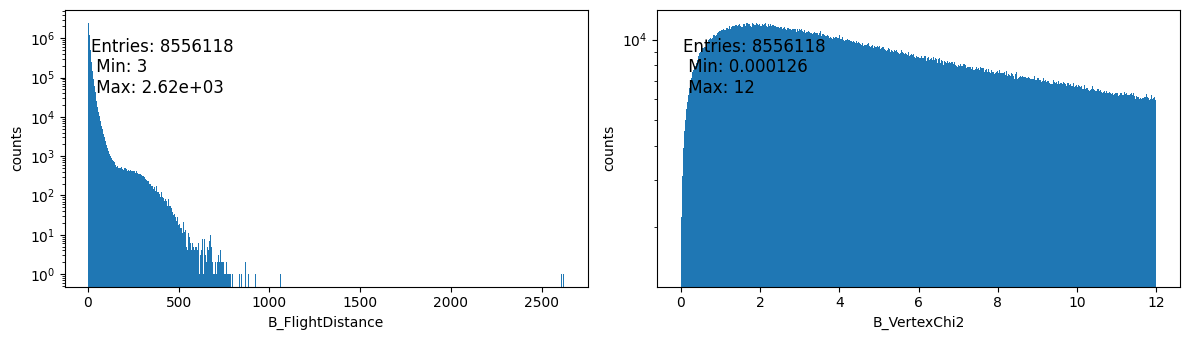

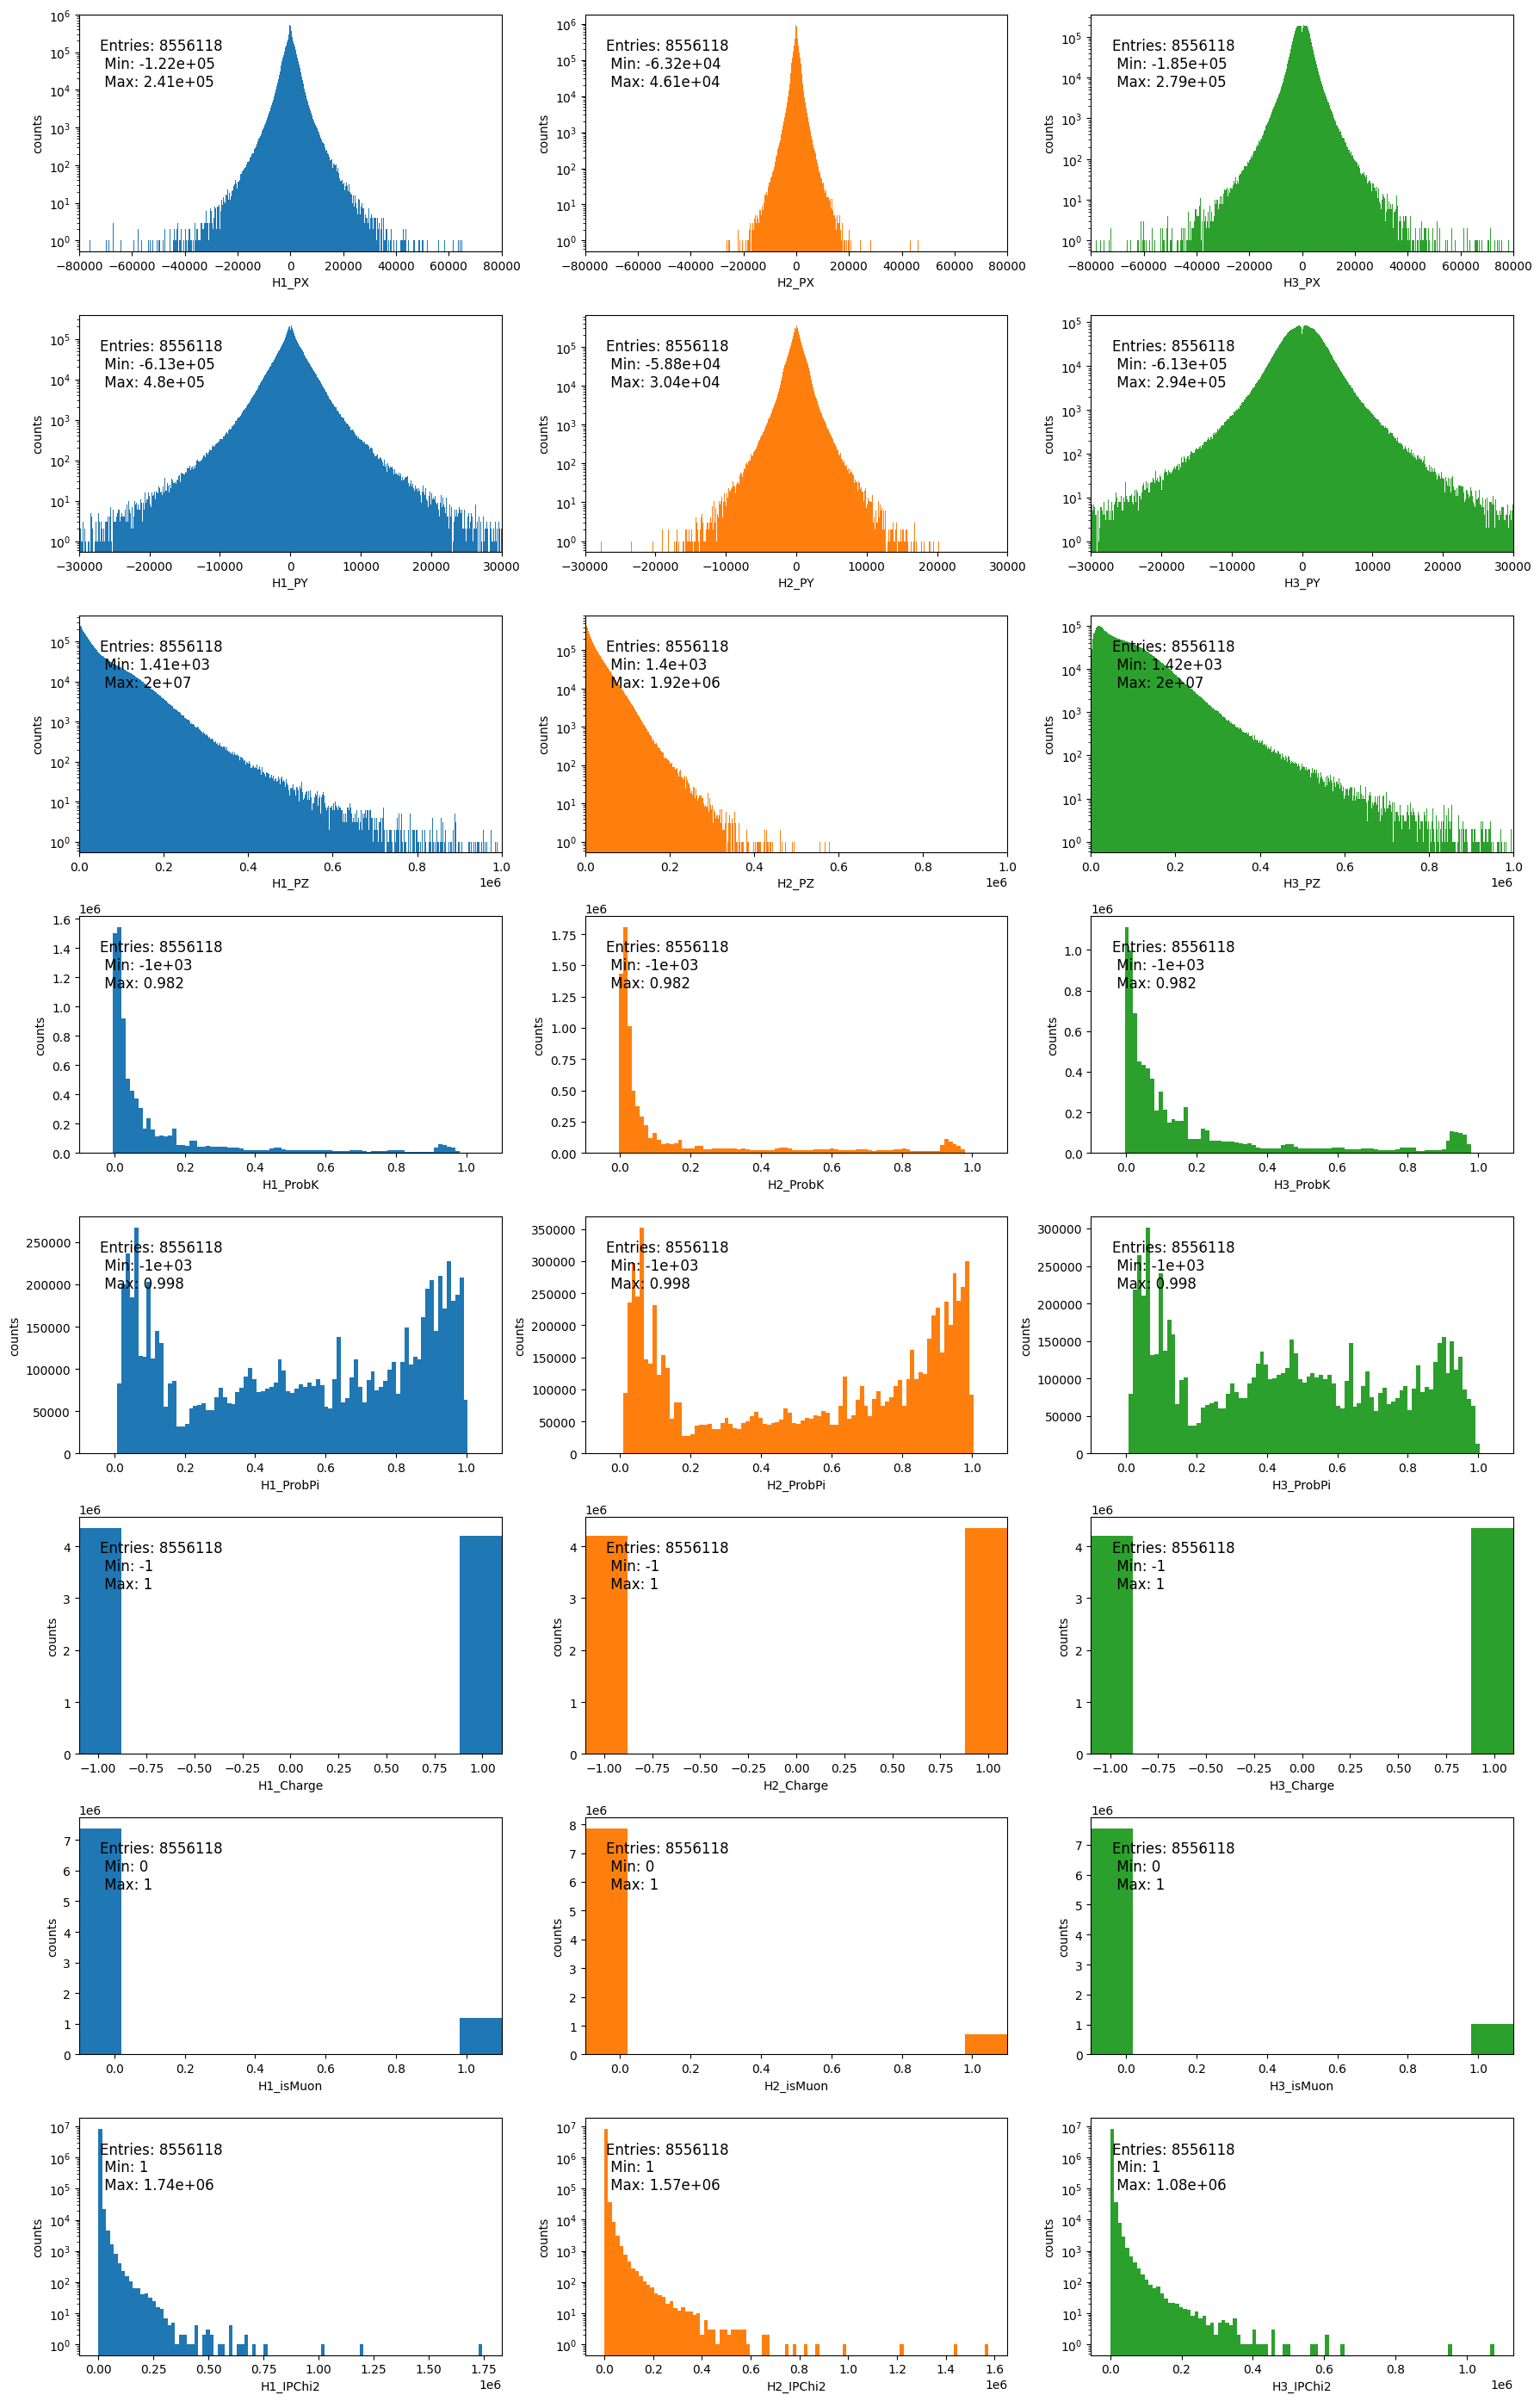

In [11]:
figs = lf.plot_all_features(all_data, lf.GLOBAL_FEATURES, lf.PRODUCT_FEATURES + lf.EXTRA_PRODUCT_FEATURES,
                            lf.PLOT_SETTINGS["raw"], cfg.n_products)

In [12]:
# keep only the columns needed by the analysis
data = all_data[cfg.columns].copy()
del all_data
print(data.columns.tolist())

['H1_PX', 'H1_PY', 'H1_PZ', 'H1_ProbK', 'H1_ProbPi', 'H1_Charge', 'H1_isMuon', 'H2_PX', 'H2_PY', 'H2_PZ', 'H2_ProbK', 'H2_ProbPi', 'H2_Charge', 'H2_isMuon', 'H3_PX', 'H3_PY', 'H3_PZ', 'H3_ProbK', 'H3_ProbPi', 'H3_Charge', 'H3_isMuon', 'magnet']


### Preselection (B -> KKK)

preselection efficiency: 0.28%


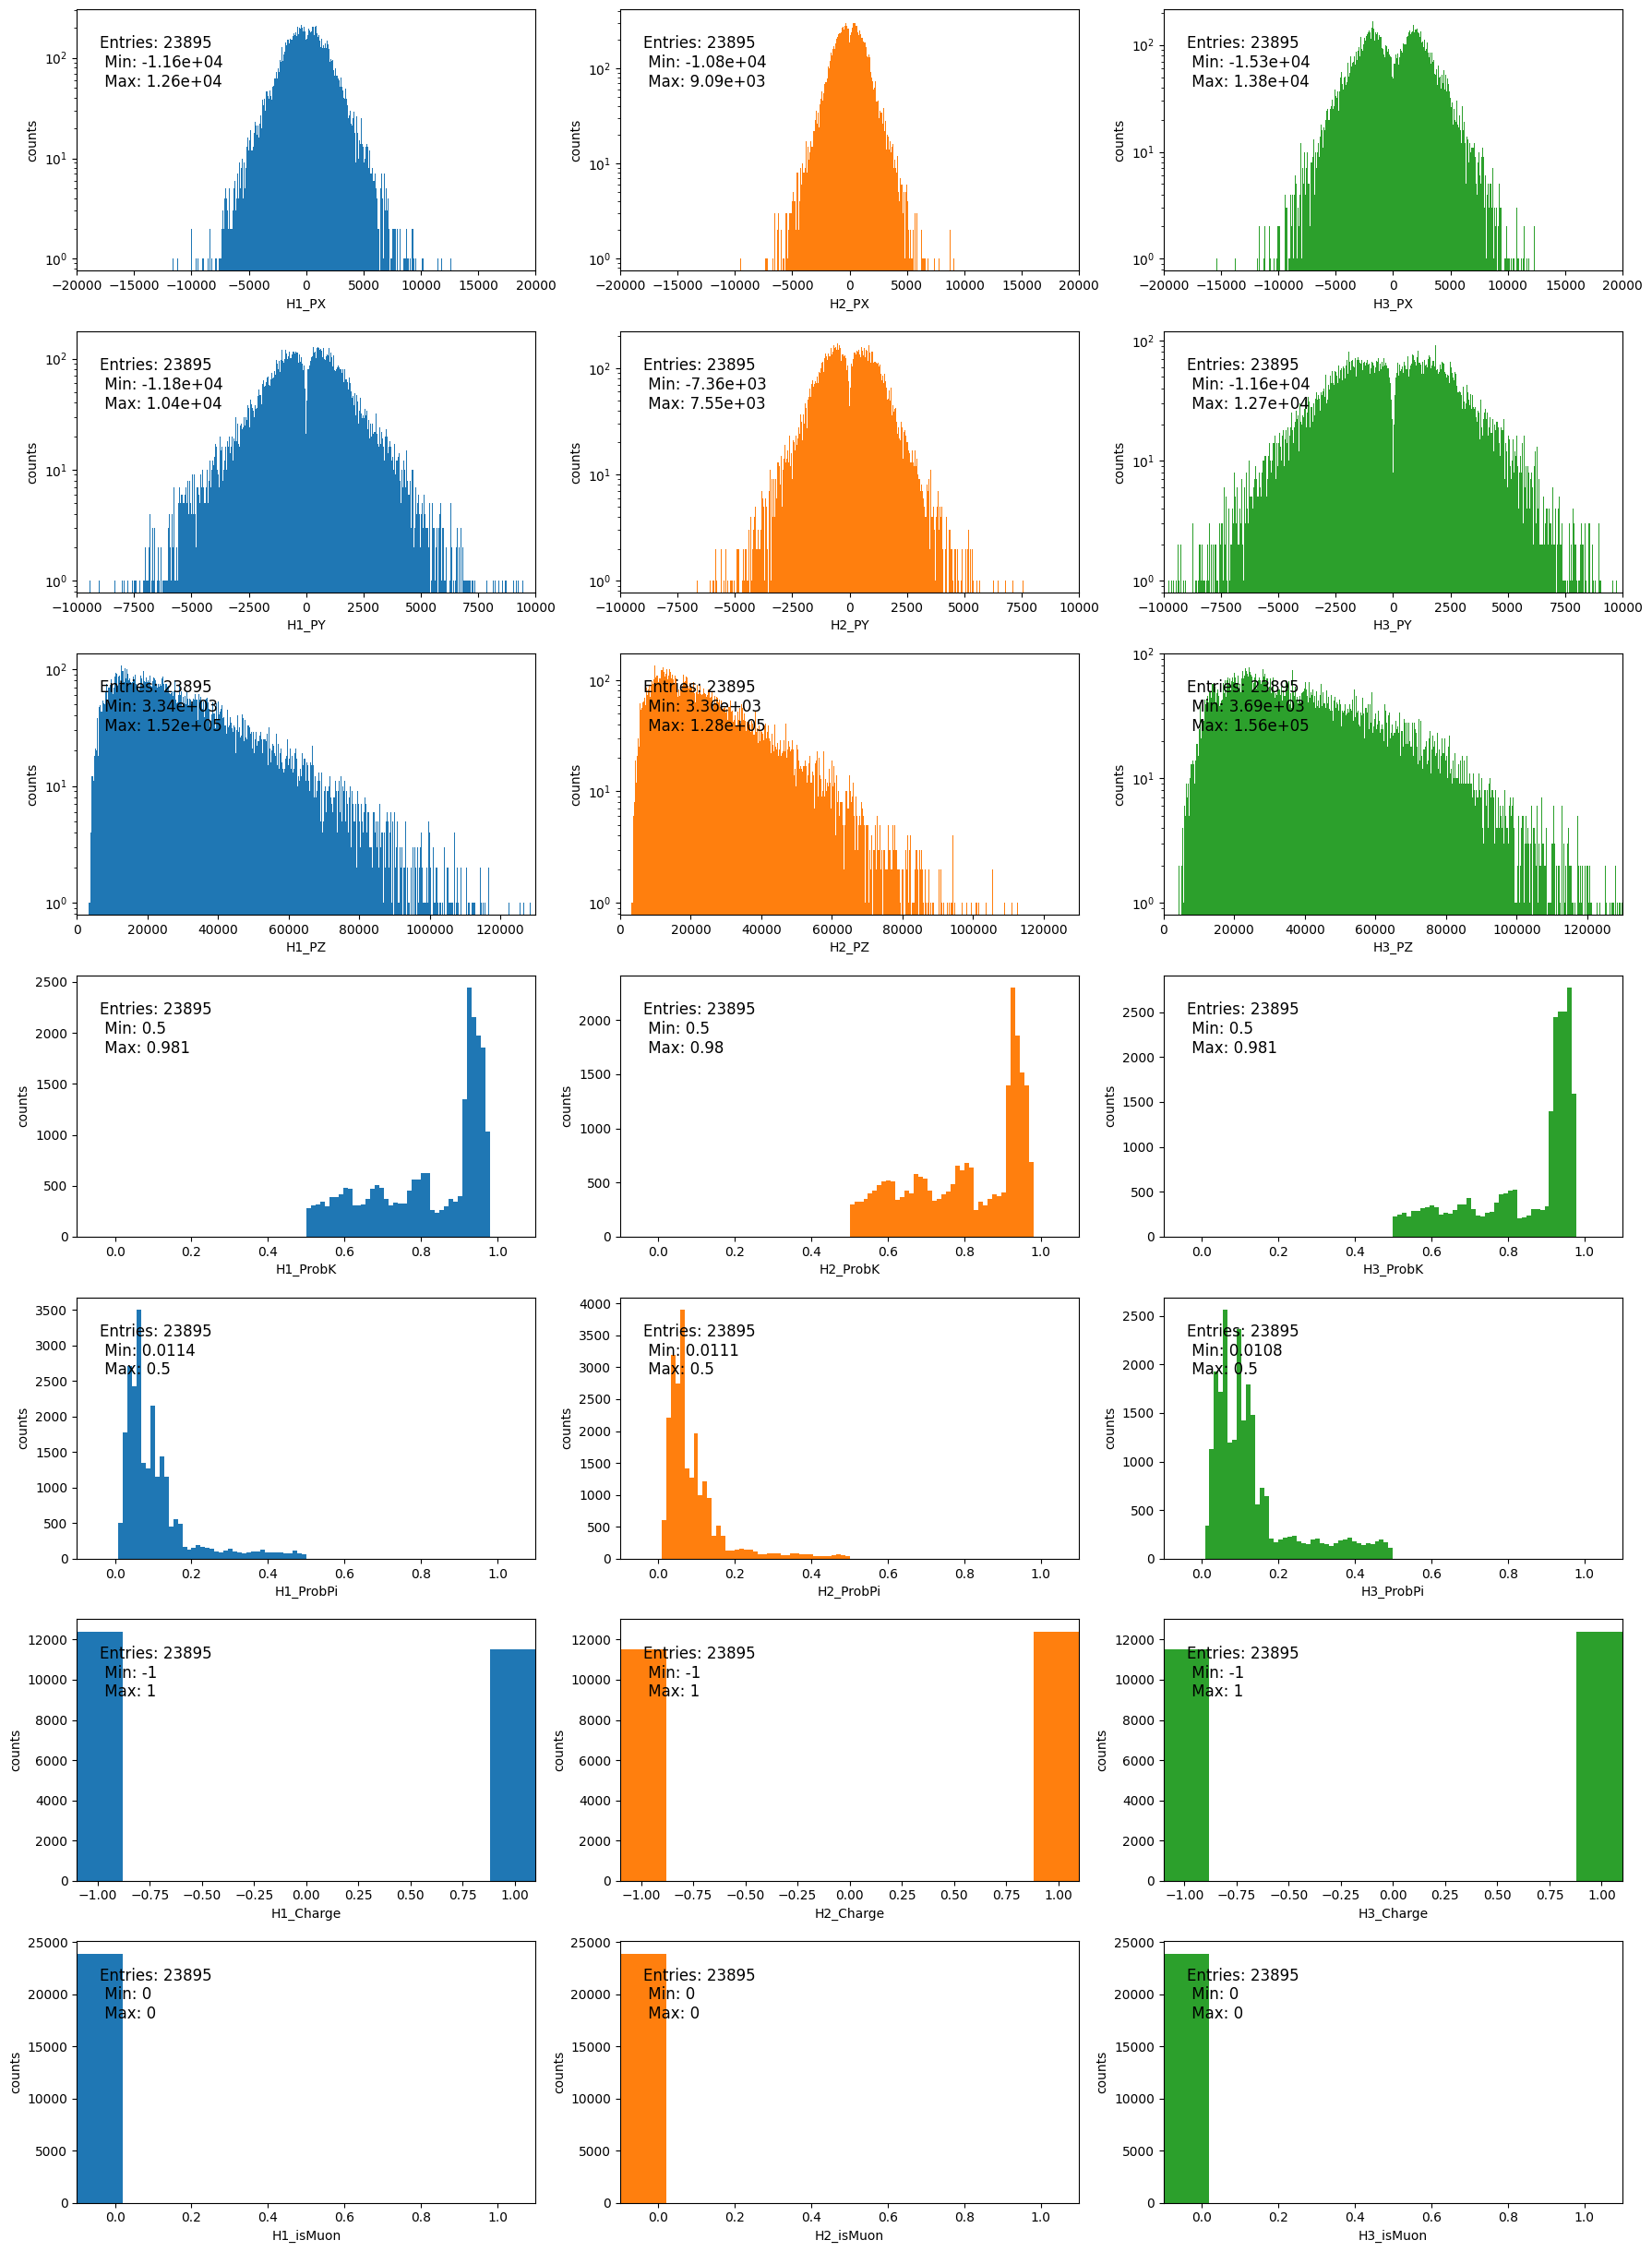

In [13]:
presel_kaon = lf.kaon_preselection(data, cfg)     # boolean mask: 3 kaons, no pions, no muons
print(f"preselection efficiency: {presel_kaon.mean():.2%}")
figs = lf.plot_all_features(data[presel_kaon], product_features=lf.PRODUCT_FEATURES,
                            settings=lf.PLOT_SETTINGS["presel"], n_products=cfg.n_products)

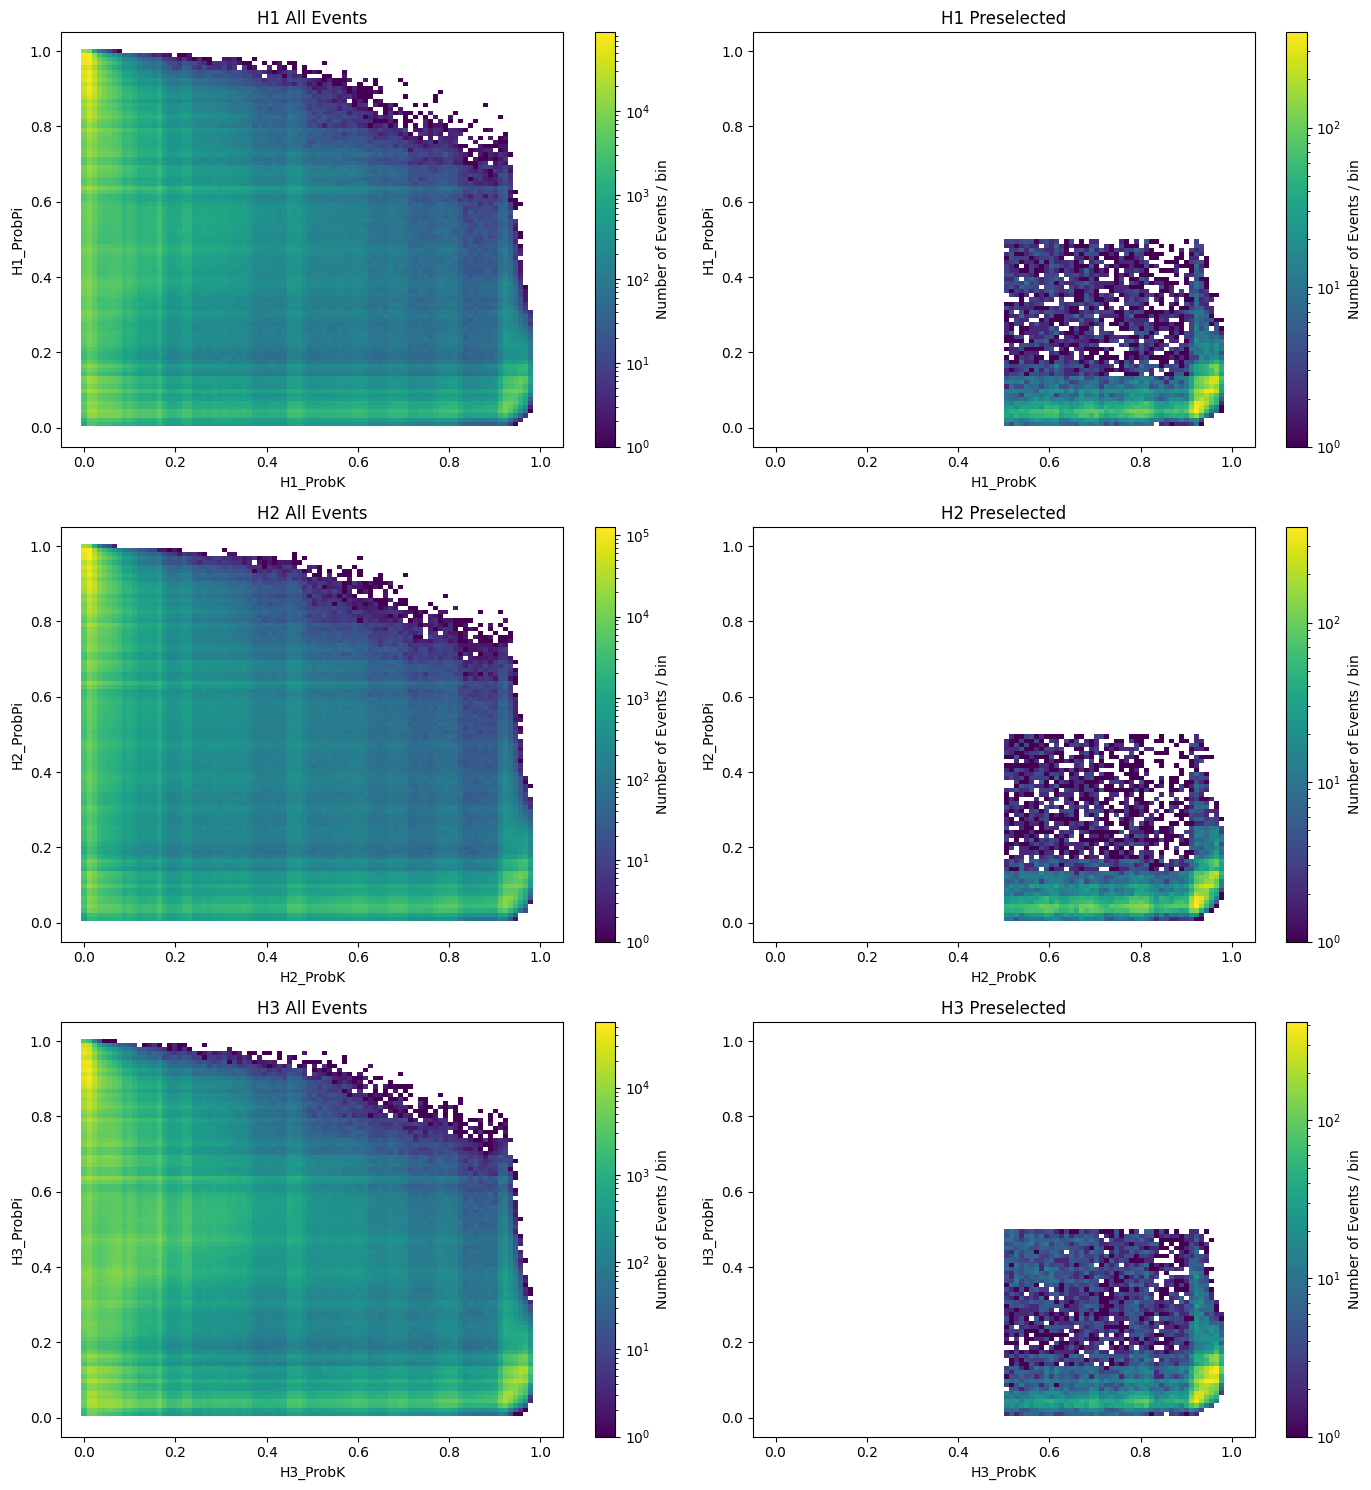

In [14]:
# 2D plot of ProbK vs ProbPi, before / after the preselection
lf.plot_pid_2d(data, data[presel_kaon], cfg);

### Preselection (B -> πππ)

preselection efficiency: 12.33%


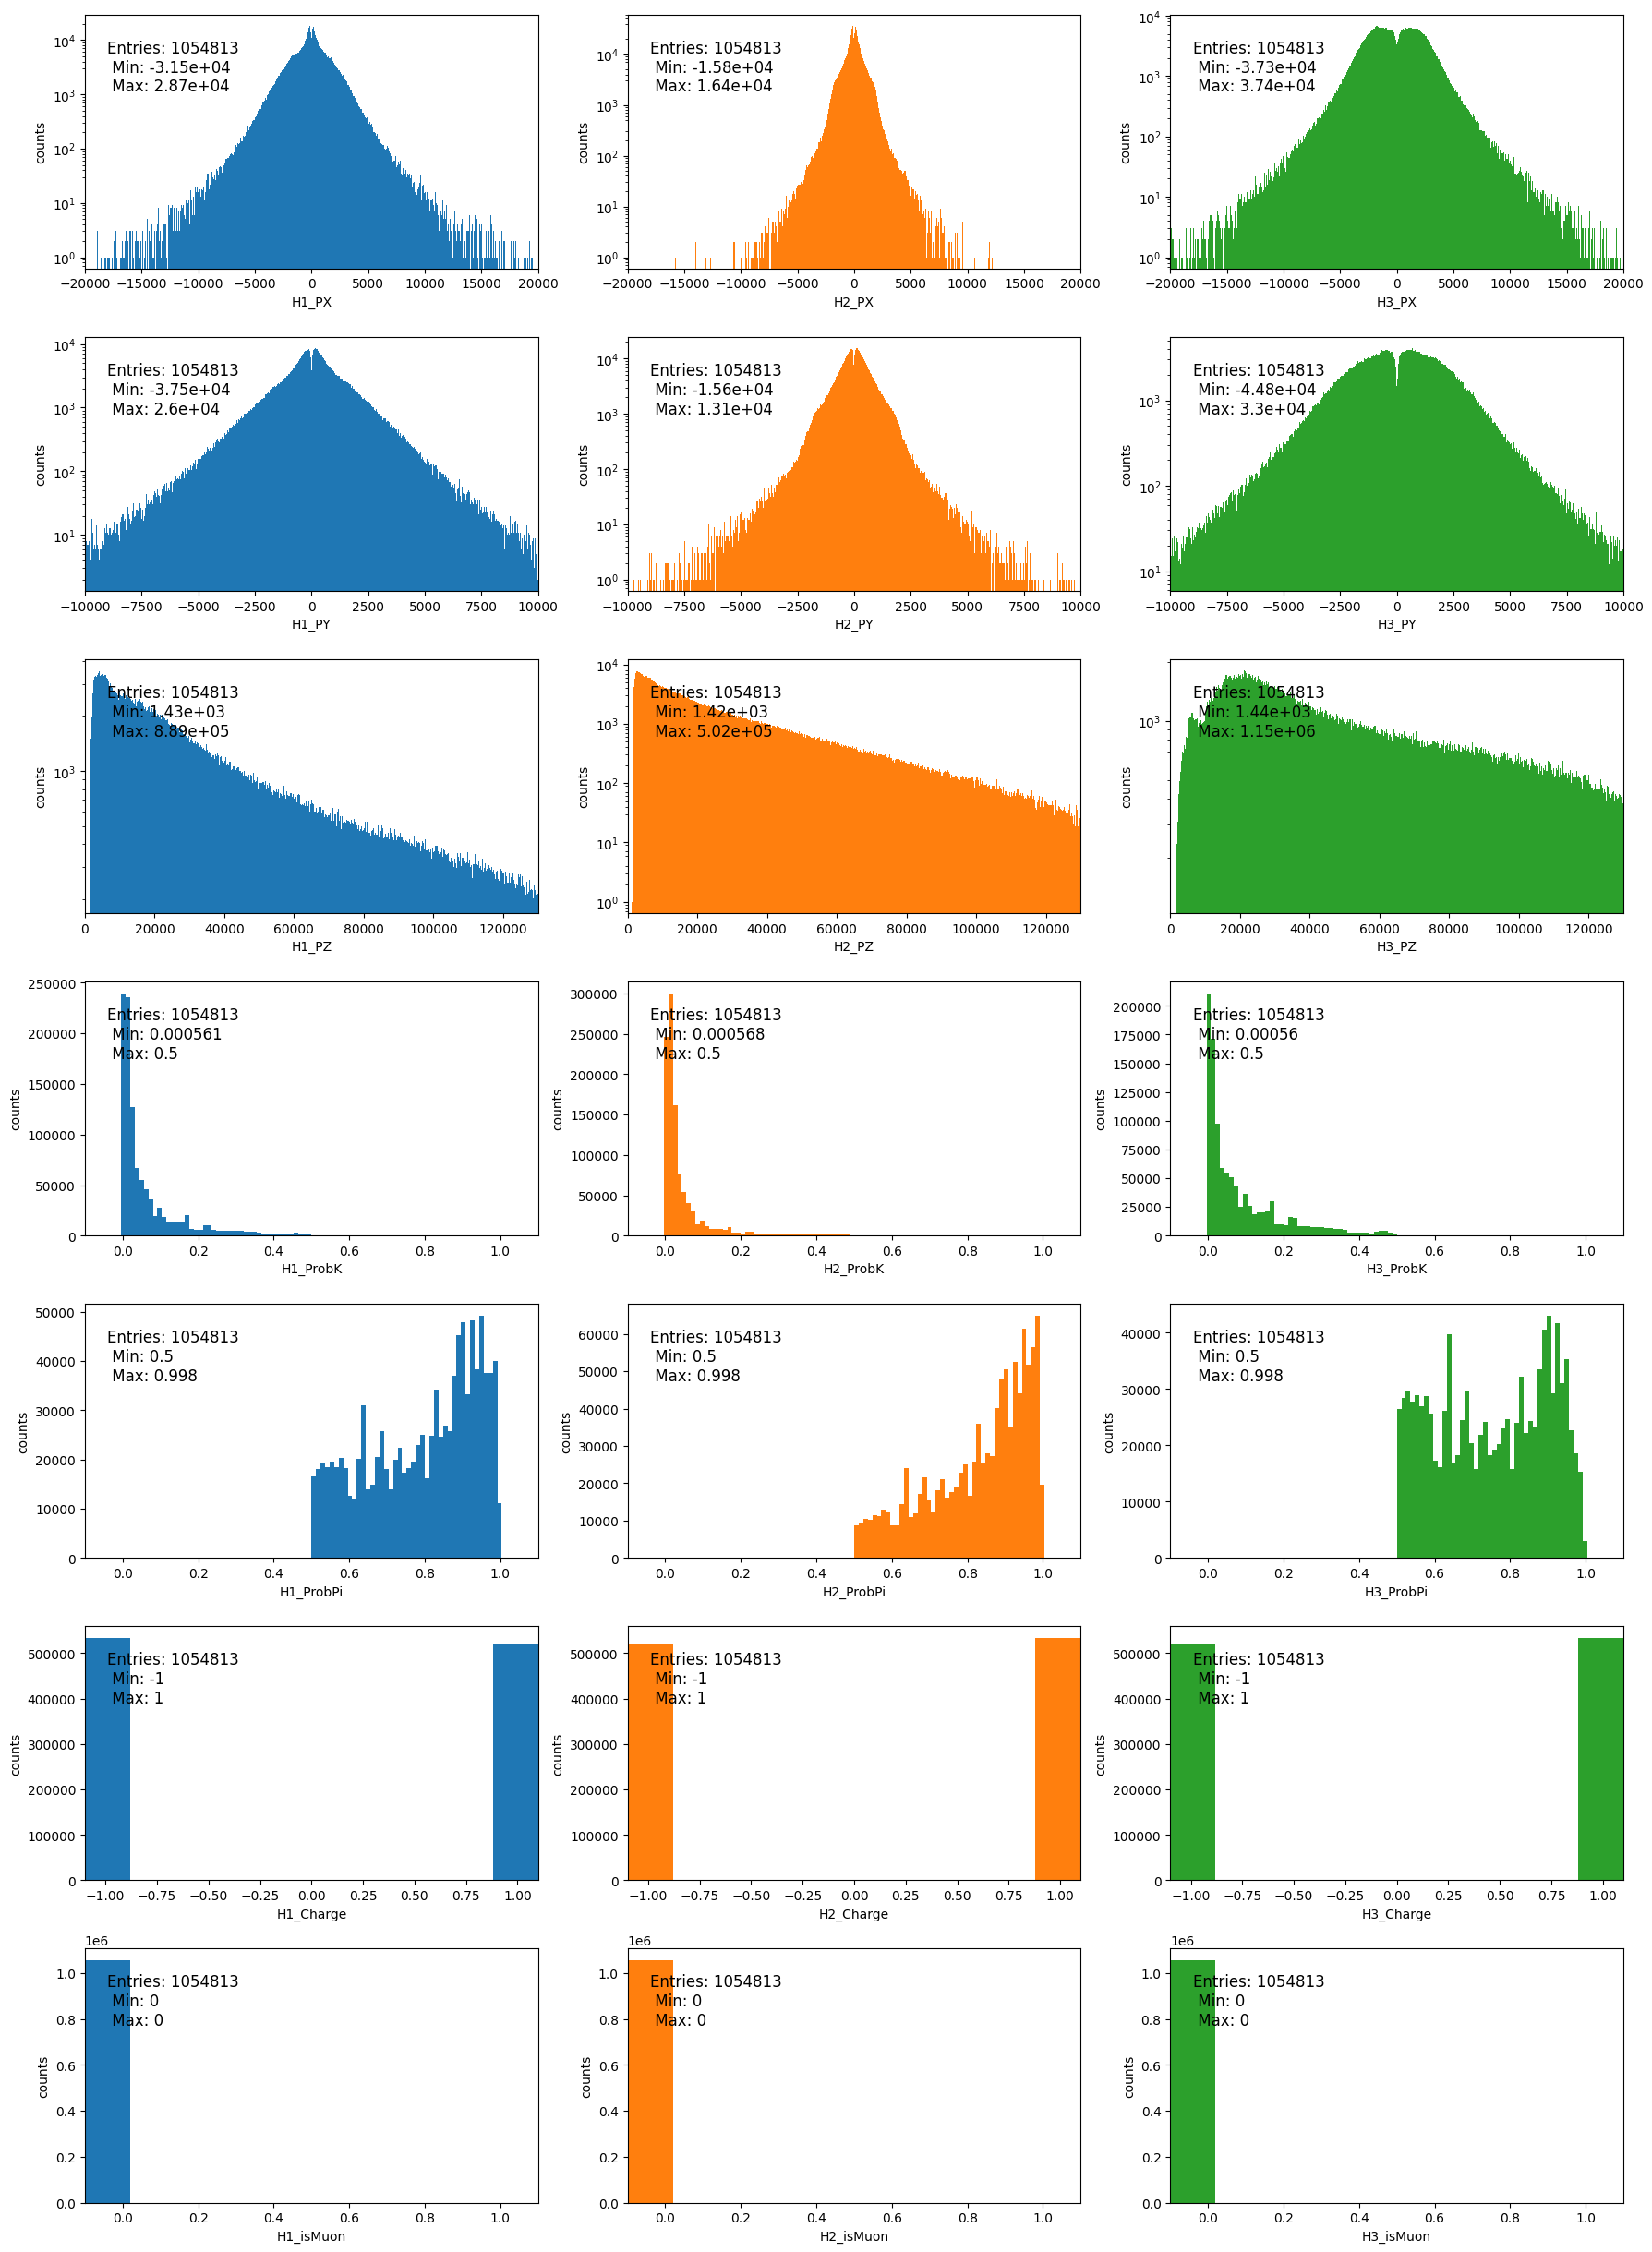

In [15]:
presel_pion = lf.pion_preselection(data, cfg)     # boolean mask: no kaons, 3 pions, no muons
print(f"preselection efficiency: {presel_pion.mean():.2%}")
figs = lf.plot_all_features(data[presel_pion], product_features=lf.PRODUCT_FEATURES,
                            settings=lf.PLOT_SETTINGS["presel"], n_products=cfg.n_products)

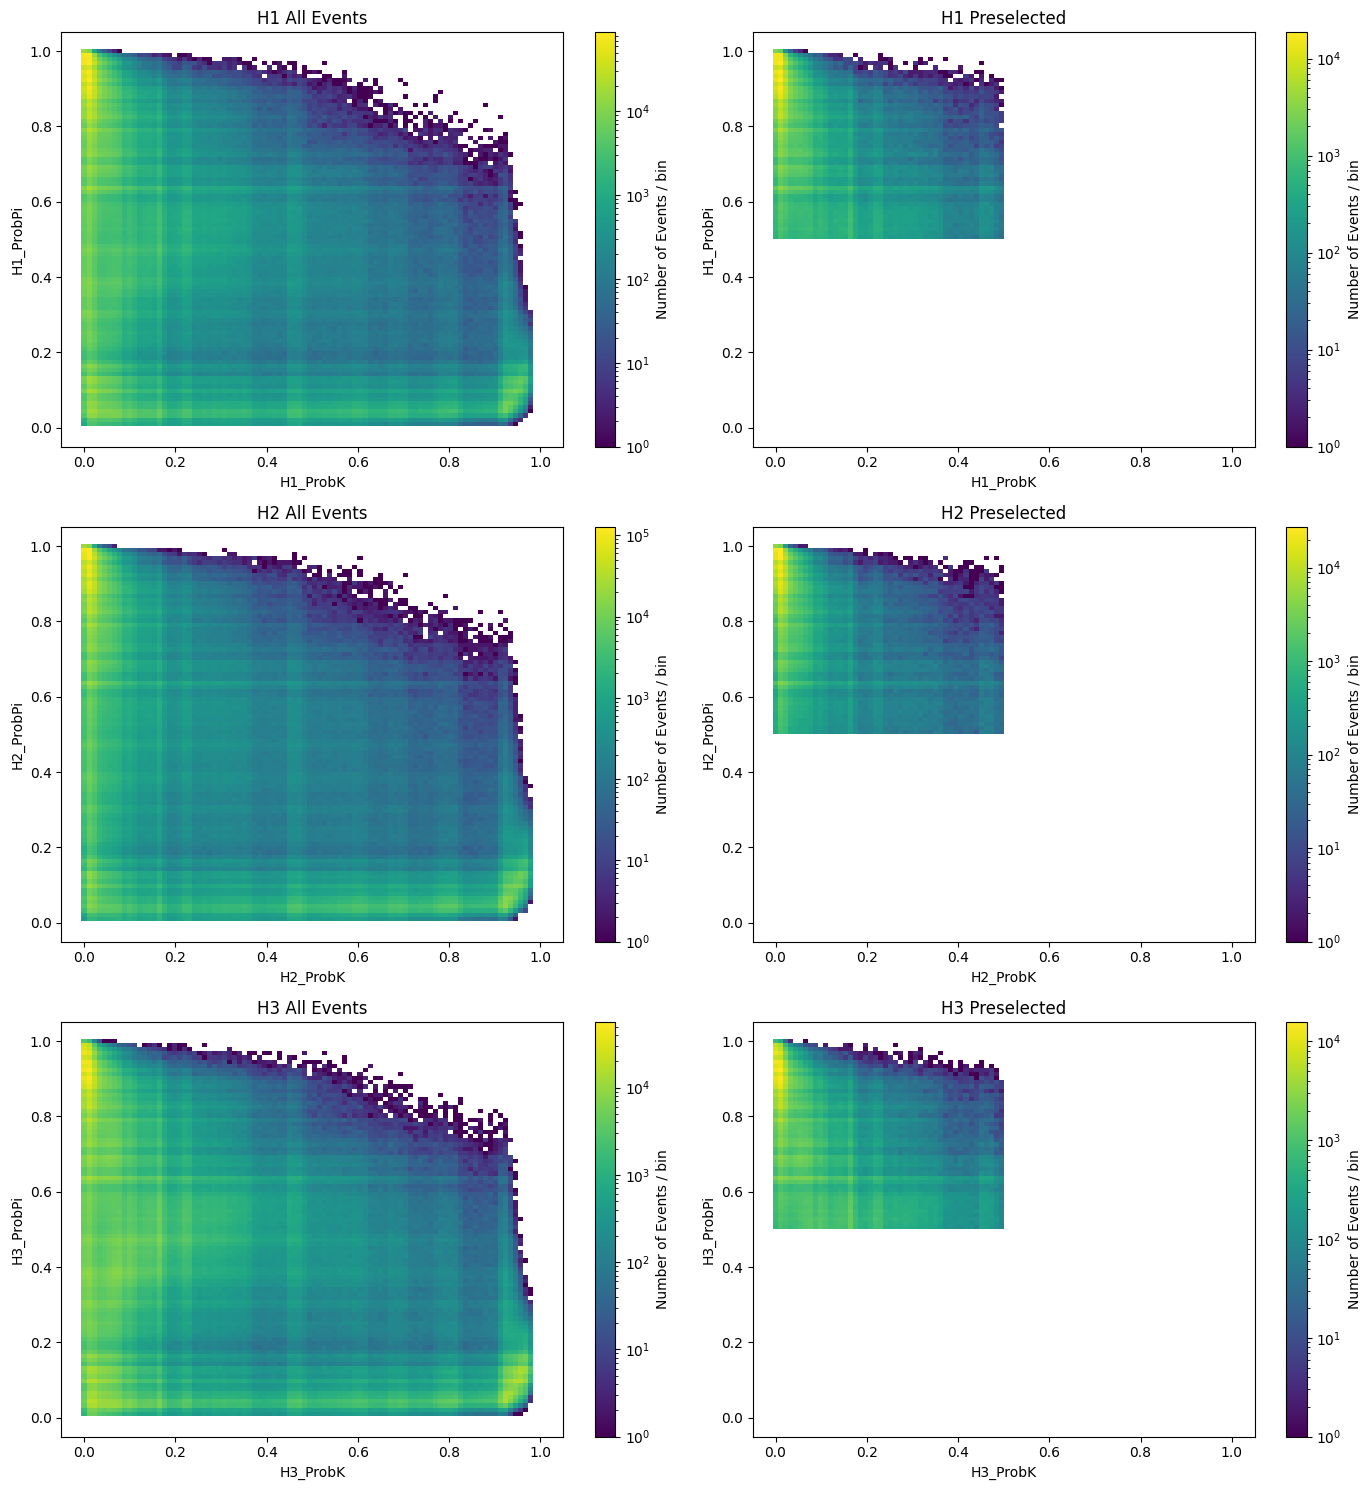

In [16]:
# 2D plot of ProbK vs ProbPi, before / after the preselection
lf.plot_pid_2d(data, data[presel_pion], cfg);

In [17]:
data_pion = data[presel_pion].reset_index(drop=True)

### Compute Invariant Mass

In [18]:
data = data[presel_kaon].reset_index(drop=True)
lf.add_B_variables(data, cfg)        # B_Mass and B_Charge (= sum of the product charges)
lf.check_charges(data, cfg)          # all charges must be +-1
print(data["B_Charge"].value_counts())

H1_Charge: [-1  1]
H2_Charge: [-1  1]
H3_Charge: [-1  1]
B_Charge
 1    12390
-1    11505
Name: count, dtype: int64


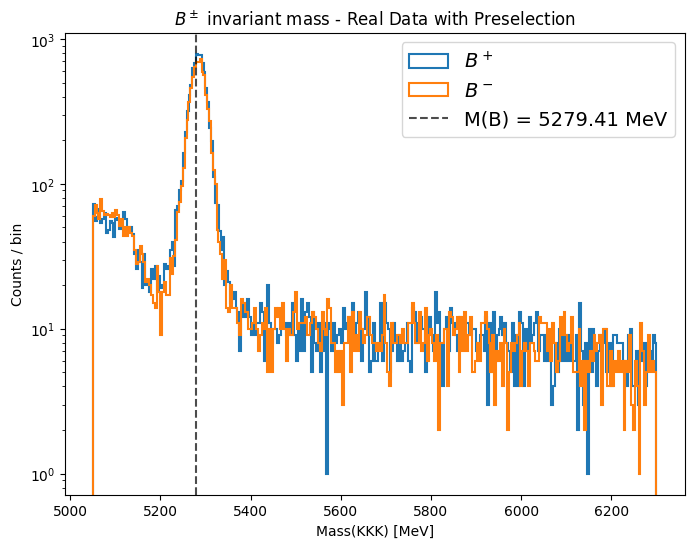

In [19]:
lf.plot_mass_by_charge(data, cfg, bins=300, logy=True, title=r"$B^\pm$ invariant mass - Real Data with Preselection");

events in fit window [5100.0, 6000.0] MeV: 21454
  B+ : 11194   B- : 10260  -->  raw A_CP = -0.043535 ± 0.006821
  magnet down: 12702   magnet up: 8752


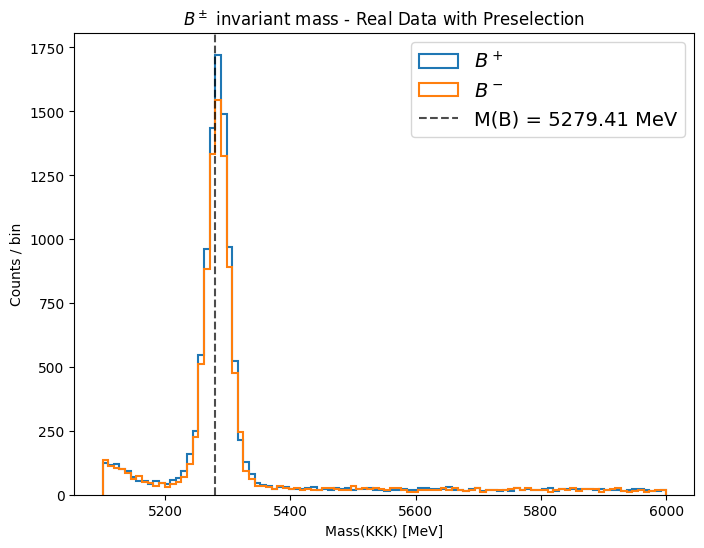

In [20]:
# cut the data in the fit window and split in B+ / B-
data_window = lf.select_window(data, cfg.fit_window)
samples = lf.split_by_charge(data_window, col='B_Mass')       # {'pos': B+ masses, 'neg': B- masses}

lf.plot_mass_by_charge(data_window, cfg, bins=100, bin_range=cfg.fit_window,
                       title=r"$B^\pm$ invariant mass - Real Data with Preselection")
lf.print_event_summary(data_window, cfg)

## Frequentist fit

Conventions (see `lhcb_freq.py`): the model is *extended* (signal yield and background yield are fit parameters),
signal = Gaussian, background = 1 or 2 exponentials (`cfg.n_exp`), both normalised in `cfg.fit_window`.
`A_CP = (N(B-) - N(B+)) / (N(B-) + N(B+))`.

### Sideband

Events in sideband (B+ / B-): 2432 / 2337 | total: 21454
Sideband pos
lam1       -> 0.019400 ± 0.002456
lam2       -> 0.000497 ± 0.000143
f_bkgs     -> 0.239133 ± 0.016035
Sideband neg
lam1       -> 0.022452 ± 0.002533
lam2       -> 0.000703 ± 0.000140
f_bkgs     -> 0.230998 ± 0.015909


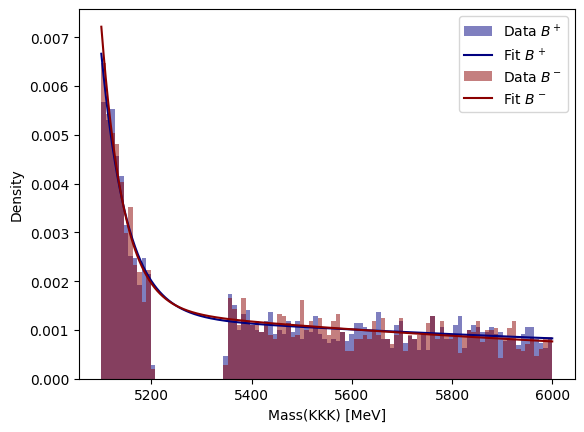

In [23]:
# Sideband = fit window without the signal region
sb_samples = {s: lf.select_sideband(m, cfg) for s, m in samples.items()}
print("Events in sideband (B+ / B-):", len(sb_samples["pos"]), "/", len(sb_samples["neg"]), "| total:", len(data_window))

sb_fits = {s: lf.fit_sideband(m, cfg) for s, m in sb_samples.items()}
for s, f in sb_fits.items():
    print(f"Sideband {s}")
    lf.print_params(f)
lf.plot_sideband(sb_samples, sb_fits, cfg);

In [233]:
# Background expected in the signal region (extrapolated from the sideband) vs observed events
for s, m in samples.items():
    b = lf.expected_background_in_signal(sb_fits[s], len(sb_samples[s]), cfg)
    print(f"{s}: expected background b = {b:.1f},  observed N_obs = {lf.in_region(m, cfg.sig_region).sum()}")

pos: expected background b = 522.0,  observed N_obs = 8762
neg: expected background b = 501.3,  observed N_obs = 7923


### Separate fits (B+ and B-)

In [234]:
sep_fits = {s: lf.fit_single(m, cfg) for s, m in samples.items()}
for s, f in sep_fits.items():
    print(s, "valid:", f.valid)
    display(f)
a, da = lf.asymmetry_from_yields(sep_fits)
print(f"A_CP (separate fits) = {a:.4f} ± {da:.4f}")

pos valid: True


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -6.5e+04                   │              Nfcn = 226              │
│ EDM = 0.000175 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig  │  8.07e3   │  0.10e3   │            │            │    0    │         │       │
│ 1 │ mu     │ 5.28433e3 │ 0.00022e3 │            │            │  5200   │  5350   │       │
│ 2 │ sigma  │   18.18   │   0.21    │            │            │    1    │   100   │       │
│ 3 │ N_bkg  │  3.13e3   │  0.07e3   │            │            │    0    │         │       │
│ 4 │ lam1   │  0.0120   │  0.0027   │            │            │  1e-06  │    1    │       │
│ 5 │ lam2   │  0.44e-3  │  0.25e-3  │            │            │  1e-06  │    1    │       │
│ 6 │ f_bkgs │   0.29    │   0.05    │            │            │    0    │    1    │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌────────┬─────────────────────────────────────────────────────────────────────────────────────┐
│        │       N_sig          mu       sigma       N_bkg        lam1        lam2      f_bkgs │
├────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│  N_sig │    9.62e+03       -1.18        4.96        -2e3   74.366e-3  3.97065e-3     -1.2109 │
│     mu │       -1.18        0.05       -0.00        1.18      -91e-6    -7.46e-6      0.0018 │
│  sigma │        4.96       -0.00      0.0434       -4.96      232e-6    12.35e-6     -0.0038 │
│  N_bkg │        -2e3        1.18       -4.96    4.68e+03  -74.369e-3 -3.97083e-3      1.2110 │
│   lam1 │   74.366e-3      -91e-6      232e-6  -74.369e-3    7.13e-06     0.56e-6     -130e-6 │
│   lam2 │  3.97065e-3    -7.46e-6    12.35e-6 -3.97083e-3     0.56e-6    6.34e-08   -11.86e-6 │
│ f_bkgs │     -1.2109      0.0018     -0.0038      1.2110     -130e-6   -11.86e-6     0.00268 │
└────────┴─────────────────────────────────────────────────────────────────────────────────────┘

neg valid: True


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -5.753e+04                 │              Nfcn = 193              │
│ EDM = 7.81e-06 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig  │  7.36e3   │  0.09e3   │            │            │    0    │         │       │
│ 1 │ mu     │ 5.28446e3 │ 0.00023e3 │            │            │  5200   │  5350   │       │
│ 2 │ sigma  │   18.12   │   0.19    │            │            │    1    │   100   │       │
│ 3 │ N_bkg  │  2.90e3   │  0.06e3   │            │            │    0    │         │       │
│ 4 │ lam1   │  0.0219   │  0.0027   │            │            │  1e-06  │    1    │       │
│ 5 │ lam2   │  0.81e-3  │  0.14e-3  │            │            │  1e-06  │    1    │       │
│ 6 │ f_bkgs │   0.203   │   0.020   │            │            │    0    │    1    │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌────────┬────────────────────────────────────────────────────────────────────────────────────────────┐
│        │        N_sig           mu        sigma        N_bkg         lam1         lam2       f_bkgs │
├────────┼────────────────────────────────────────────────────────────────────────────────────────────┤
│  N_sig │     8.07e+03        -0.23         2.39         -1e3     2.594e-3 -1.694911e-3     150.7e-3 │
│     mu │        -0.23       0.0526        -0.00         0.23       -57e-6    -0.990e-6       0.3e-3 │
│  sigma │         2.39        -0.00       0.0371        -2.39        21e-6    -5.230e-6       0.4e-3 │
│  N_bkg │         -1e3         0.23        -2.39      3.6e+03    -2.594e-3  1.694913e-3    -150.7e-3 │
│   lam1 │     2.594e-3       -57e-6        21e-6    -2.594e-3      7.2e-06     0.197e-6       -38e-6 │
│   lam2 │ -1.694911e-3    -0.990e-6    -5.230e-6  1.694913e-3     0.197e-6     2.04e-08    -2.074e-6 │
│ f_bkgs │     150.7e-3       0.3e-3       0.4e-3    -150.7e-3       -38e-6    -2.074e-6     0.000393 │
└────────┴────────────────────────────────────────────────────────────────────────────────────────────┘

A_CP (separate fits) = -0.0454 ± 0.0086


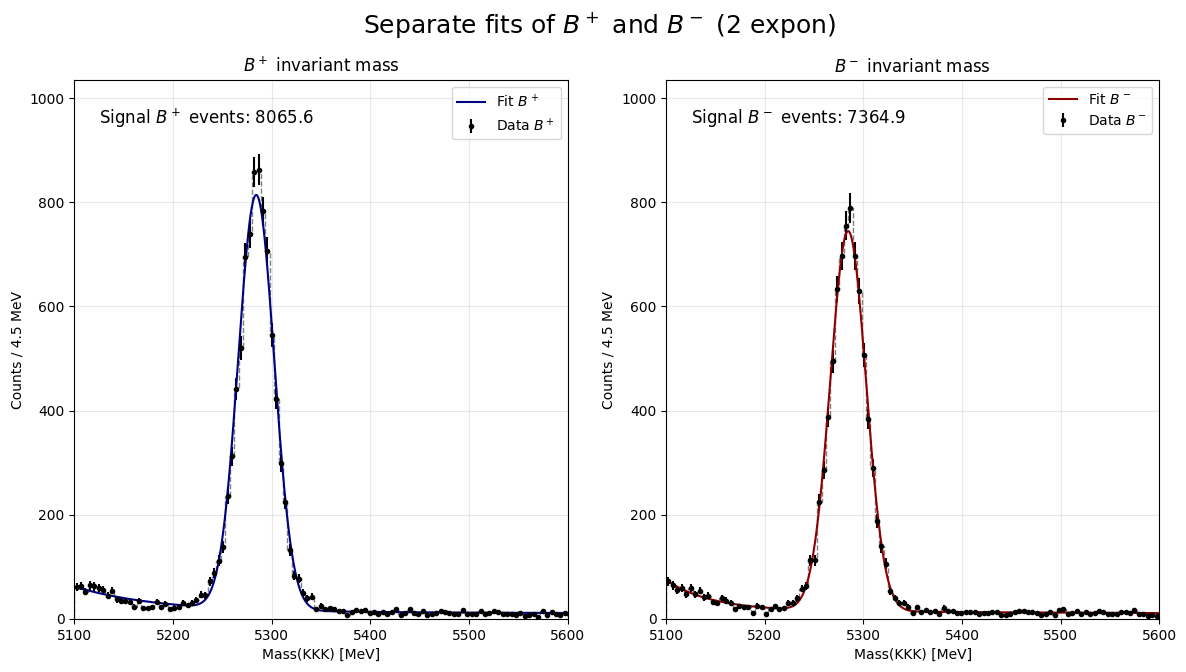

In [235]:
lf.plot_separate_fits(sep_fits, samples, cfg);

#### Goodness of fit ($\chi^2$)

In [236]:
for s, m in samples.items():
    f = sep_fits[s]
    print(f"--- {s}")
    print(lf.chi2_gof(m, lf.fitted_curve(f, cfg), cfg.fit_window, bins=200, n_free=f.nfit))

--- pos
Chi2:         262.58
NDOF:         193
Chi2 / NDOF:  1.360
p-value:      0.0006
--- neg
Chi2:         199.97
NDOF:         193
Chi2 / NDOF:  1.036
p-value:      0.3503


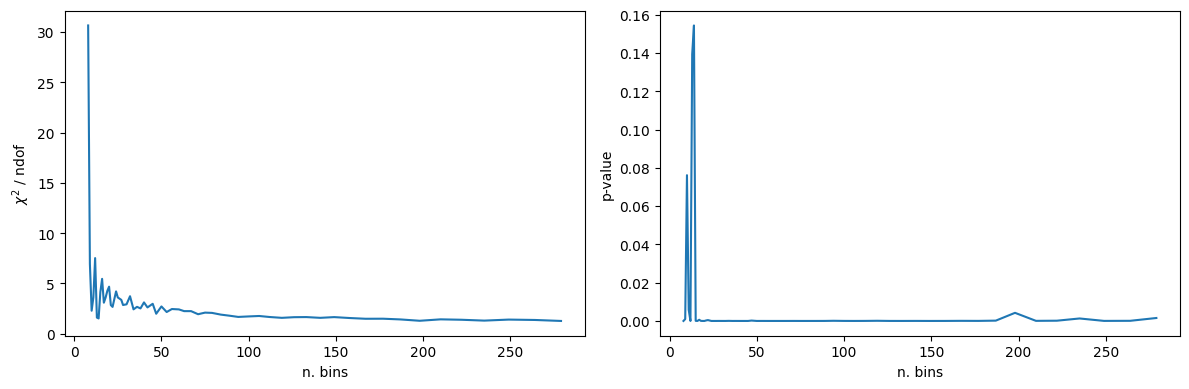

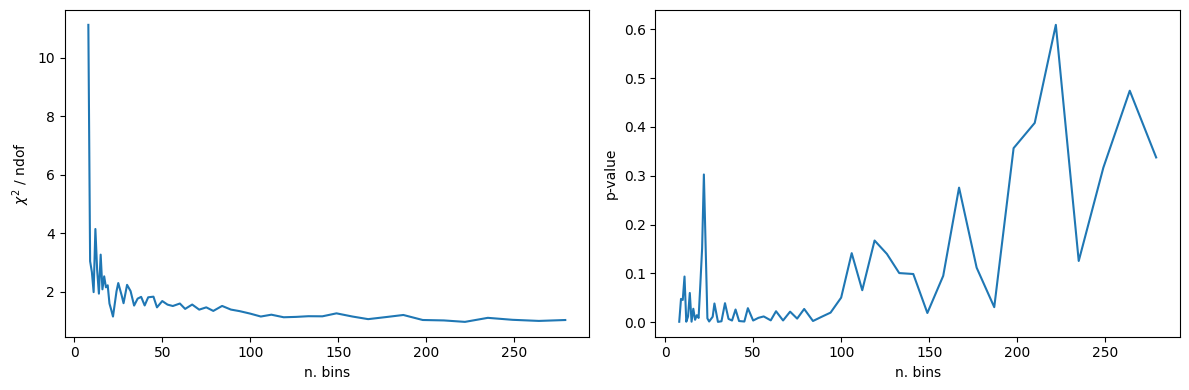

In [237]:
# chi2/ndof and p-value as a function of the number of bins (B+)
bin_values = np.unique(np.logspace(0, 3.5, 100, base=5).astype(int))
f = sep_fits["pos"]
chi2_red, p_vals = lf.scan_gof_bins(samples["pos"], lf.fitted_curve(f, cfg), cfg.fit_window, f.nfit, bin_values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(bin_values, chi2_red); axes[0].set(xlabel="n. bins", ylabel=r"$\chi^2$ / ndof")
axes[1].plot(bin_values, p_vals);   axes[1].set(xlabel="n. bins", ylabel="p-value")
fig.tight_layout()

# chi2/ndof and p-value as a function of the number of bins (B-)
bin_values = np.unique(np.logspace(0, 3.5, 100, base=5).astype(int))
f = sep_fits["neg"]
chi2_red, p_vals = lf.scan_gof_bins(samples["neg"], lf.fitted_curve(f, cfg), cfg.fit_window, f.nfit, bin_values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(bin_values, chi2_red); axes[0].set(xlabel="n. bins", ylabel=r"$\chi^2$ / ndof")
axes[1].plot(bin_values, p_vals);   axes[1].set(xlabel="n. bins", ylabel="p-value")
fig.tight_layout()

### Joint Fit

I want to do a joint fot for the B+ and B- peaks. 

The common parameters are:

- mu:    B+/B- mass, the same = 5279.15 MeV
- sigma: resolution, the same for B+/B- because the detector is symmetric
- N_sig: signal events (B+ and B-)
- A_CP:  CP asymmetry (N_sig_neg - N_sig_pos) / (N_sig_neg + N_sig_pos)

Specific parameters:

- For B+
    - N_bkg_pos:  events of bkgs
    - lam1_pos:   bkg1
    - lam2_pos:   bkg2
    - f_bkgs_pos: fraction of contribution bkg1 respect bkg2

- For B-
    - N_bkg_neg:  events of bkgs
    - lam1_neg:   bkg1
    - lam2_neg:   bkg2
    - f_bkgs_neg: fraction of contribution bkg1 respect bkg2

In [238]:
# 2 exponentials (default) and 1 exponential (simpler background model)
joint = {n: lf.fit_joint(samples, cfg, n_exp=n, minos=True) for n in (2, 1)}
display(joint[1])
display(joint[2])

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -1.221e+05                 │              Nfcn = 835              │
│ EDM = 6.96e-05 (Goal: 0.0002)    │            time = 1.6 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name      │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼───────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig     │  15.03e3  │  0.13e3   │  -0.13e3   │   0.13e3   │    0    │         │       │
│ 1 │ A_CP      │  -0.048   │   0.008   │   -0.008   │   0.009    │   -1    │    1    │       │
│ 2 │ mu        │ 5.28439e3 │ 0.00016e3 │ -0.00016e3 │ 0.00016e3  │  5200   │  5350   │       │
│ 3 │ sigma     │   17.57   │   0.13    │   -0.13    │    0.13    │    1    │   100   │       │
│ 4 │ N_bkg_pos │  3.32e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 5 │ lam1_pos  │  2.09e-3  │  0.08e-3  │  -0.08e-3  │  0.08e-3   │  1e-06  │    1    │       │
│ 6 │ N_bkg_neg │  3.10e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 7 │ lam1_neg  │  2.11e-3  │  0.08e-3  │  -0.08e-3  │  0.08e-3   │  1e-06  │    1    │       │
└───┴───────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         N_sig         │         A_CP          │          mu           │         sigma         │       N_bkg_pos       │       lam1_pos        │       N_bkg_neg       │       lam1_neg        │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │  -0.13e3  │  0.13e3   │  -0.008   │   0.009   │   -0.16   │   0.16    │   -0.13   │   0.13    │    -60    │    60     │ -0.08e-3  │  0.08e-3  │    -60    │    60     │ -0.08e-3  │  0.08e-3  │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ Max FCN  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ New Min  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
└──────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┘
┌───────────┬──────────────────────────────────────────────────────────────────────────────

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -1.225e+05                 │             Nfcn = 3081              │
│ EDM = 4.86e-05 (Goal: 0.0002)    │            time = 6.8 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name       │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig      │  15.43e3  │  0.13e3   │  -0.13e3   │   0.13e3   │    0    │         │       │
│ 1 │ A_CP       │  -0.045   │   0.008   │   -0.008   │   0.008    │   -1    │    1    │       │
│ 2 │ mu         │ 5.28440e3 │ 0.00016e3 │ -0.00016e3 │ 0.00016e3  │  5200   │  5350   │       │
│ 3 │ sigma      │   18.15   │   0.14    │   -0.14    │    0.14    │    1    │   100   │       │
│ 4 │ N_bkg_pos  │  3.13e3   │  0.07e3   │  -0.07e3   │   0.07e3   │    0    │         │       │
│ 5 │ lam1_pos   │  0.0118   │  0.0026   │  -0.0021   │   0.0026   │  1e-06  │    1    │       │
│ 6 │ lam2_pos   │  0.42e-3  │  0.26e-3  │  -0.26e-3  │  0.22e-3   │  1e-06  │    1    │       │
│ 7 │ f_bkgs_pos │   0.29    │   0.05    │   -0.04    │    0.05    │    0    │    1    │       │
│ 8 │ N_bkg_neg  │  2.89e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 9 │ lam1_neg   │  0.0220   │  0.0027   │  -0.0025   │   0.0028   │  1e-06  │    1    │       │
│ 10│ lam2_neg   │  0.81e-3  │  0.14e-3  │  -0.14e-3  │  0.14e-3   │  1e-06  │    1    │       │
│ 11│ f_bkgs_neg │   0.203   │   0.020   │   -0.019   │   0.020    │    0    │    1    │       │
└───┴────────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         N_sig         │         A_CP          │          mu           │         sigma         │       N_bkg_pos       │       lam1_pos        │       lam2_pos        │      f_bkgs_pos       │       N_bkg_neg       │       lam1_neg        │       lam2_neg        │      f_bkgs_neg       │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │  -0.13e3  │  0.13e3   │  -0.008   │   0.008   │   -0.16   │   0.16    │   -0.14   │   0.14    │    -70    │    70     │  -0.0021  │  0.0026   │ -0.26e-3  │  0.22e-3  │   -0.04   │   0.05    │    -60    │    60     │  -0.0025  │  0.0028   │ -0.14e-3  │  0.14e-3  │  -0.019   │   0.020   │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   Fals


=== 2 exponential(s) ===  valid: True
A_CP = -0.0450 ± 0.0084   (relative error 18.8%, Hesse significance 5.33 sigma)
Chi2:         462.42
NDOF:         388
Chi2 / NDOF:  1.192
p-value:      0.0055

=== 1 exponential(s) ===  valid: True
A_CP = -0.0478 ± 0.0085   (relative error 17.8%, Hesse significance 5.62 sigma)
Chi2:         951.36
NDOF:         392
Chi2 / NDOF:  2.427
p-value:      0.0000


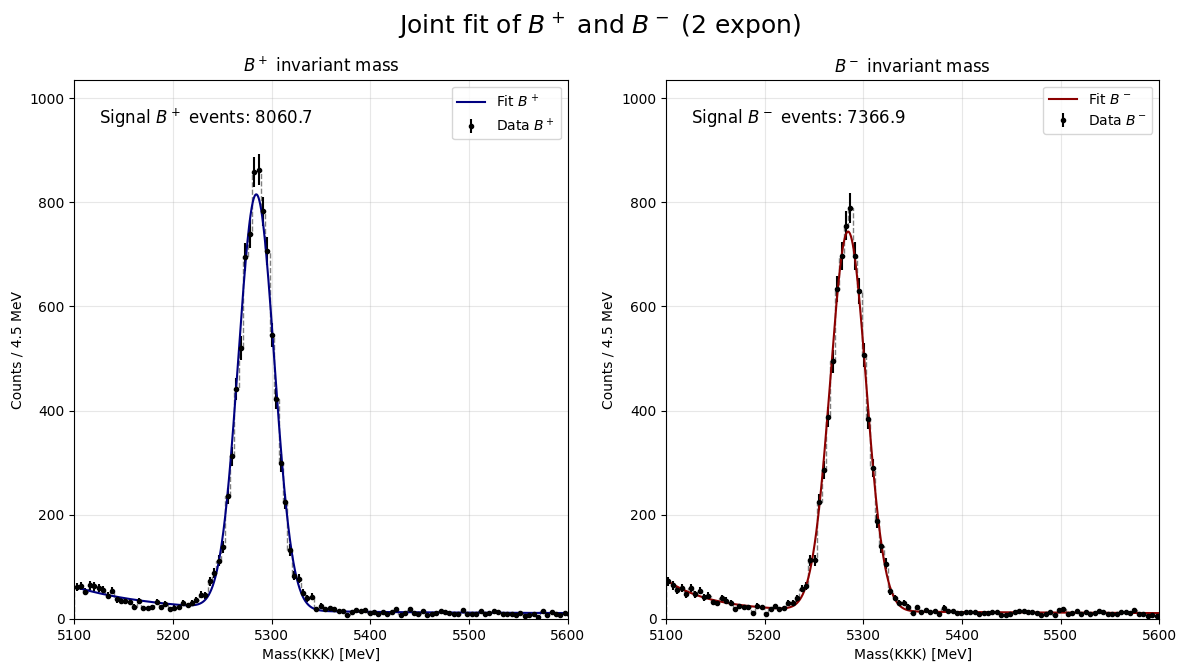

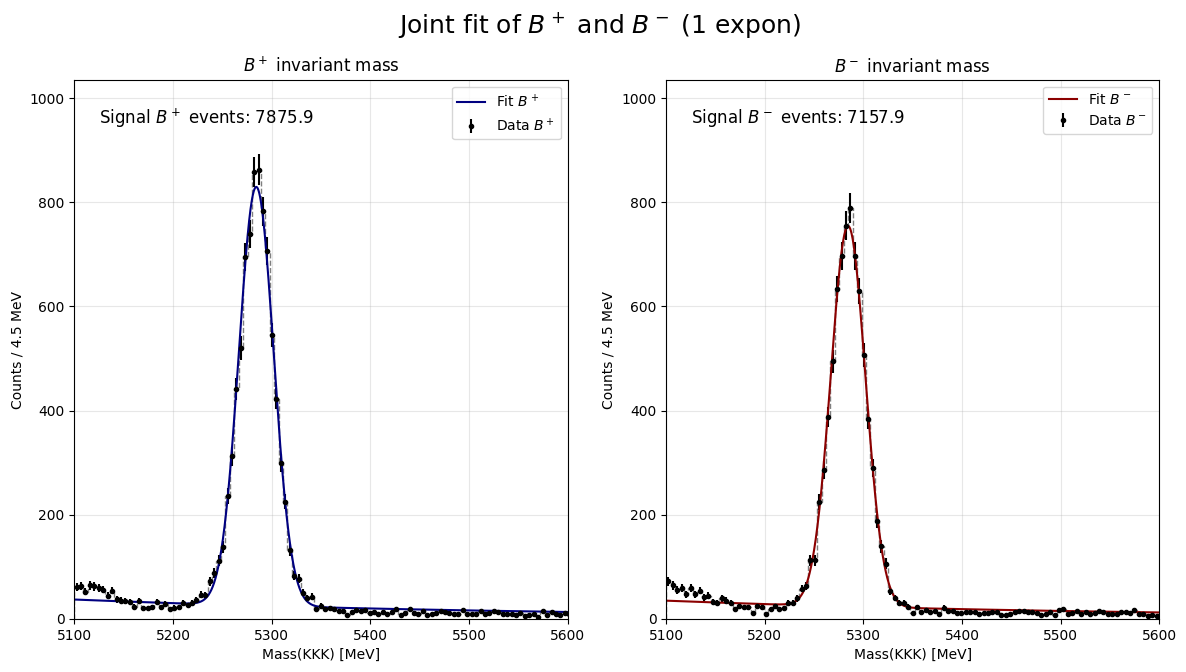

In [239]:
for n, m in joint.items():
    print(f"\n=== {n} exponential(s) ===  valid: {m.valid}")
    lf.print_asymmetry(m)
    print(lf.gof_joint(m, samples, cfg, n_exp=n))
    lf.plot_joint_fit(m, samples, cfg, n_exp=n)

### Profiled Likelihood and hypothesis test

In [240]:
best = joint[2]
POIS = ["A_CP", "mu"]                                        # parameters of interest
nuisance = [p for p in best.parameters if p not in POIS]     # everything else is profiled

t, p, _ = lf.wilks_test(best, {"A_CP": 0.0})                 # H0: no CP violation
print(f"H0: A_CP = 0  ->  t = {t:.2f},  p-value = {p:.2e}  ({scipy.stats.norm.ppf(1 - p):.2f} sigma)")

H0: A_CP = 0  ->  t = 28.34,  p-value = 1.02e-07  (5.20 sigma)


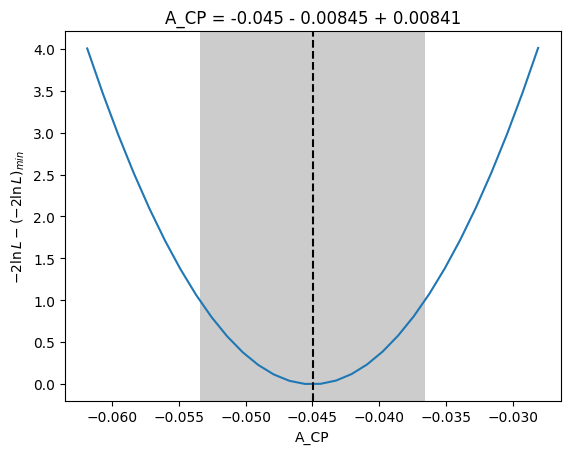

In [ ]:
best.draw_mnprofile("A_CP")
plt.ylabel(r"$-2\ln L - (-2\ln L)_{min}$");

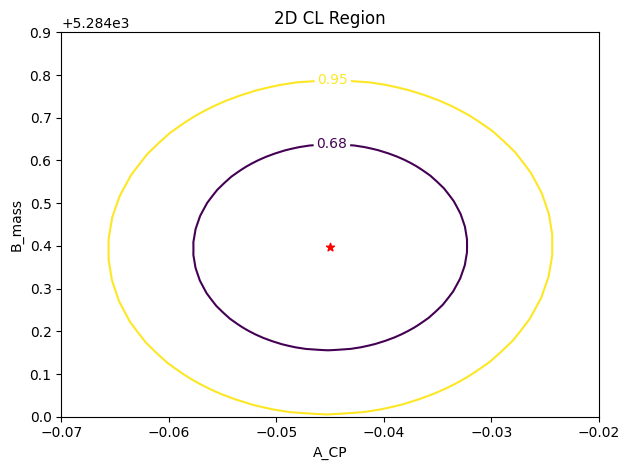

In [ ]:
best.draw_mncontour("A_CP", "mu", cl=[0.68, 0.95])
plt.scatter([best.values["A_CP"]], [best.values["mu"]], marker="*", color="r")
plt.title("2D CL Region")
plt.xlabel("A_CP")
plt.ylabel("B_mass")
plt.xlim(-0.07, -0.020)
plt.ylim(5284.0, 5284.9)
plt.tight_layout()

### Coverage check (bootstrap) of Wilks' theorem

  0%|          | 0/1000 [00:00<?, ?it/s]

coverage of the 2.30 (68.3%) threshold: 67.2%   (1000 toys, 0 failed)


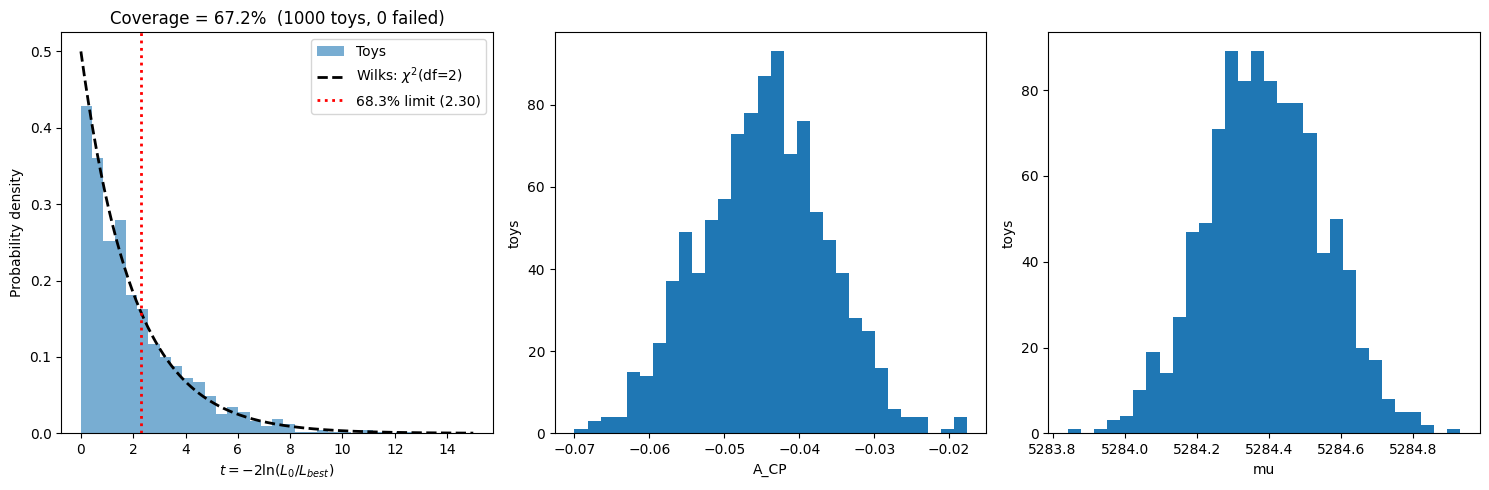

In [ ]:
res = lf.run_coverage_study(data_window, cfg, best, pois=POIS, n_toys=1000, seed=1)
print(f"coverage of the {res.t_crit:.2f} (68.3%) threshold: {res.coverage:.1%}   ({len(res.t_values)} toys, {res.n_failed} failed)")
lf.plot_coverage(res);

# Dalitz plots and two body resonances
## Aims:
* Produce Dalitz plots of the simulation and real data sample
* Create ordered and binned dalitz plots.
* Identify two body resonances in the Dalitz plots

In this stage we introduce you to an important technique for analysing decays of one particle (your charged B meson) into three bodies (the three kaons). This is known as a Dalitz plot. 

The decay of the B meson can proceed either directly to the three-body final state or via an intermediate particle. For example, B<sup>+</sup> → K<sup>+</sup>K<sup>+</sup>K<sup>−</sup>, could proceed through the decay  B<sup>+</sup> → K<sup>+</sup>R<sup>0</sup>, where R<sup>0</sup> is a neutral particle resonance which can decay R<sup>0</sup> → K<sup>+</sup>K<sup>-</sup>. Dalitz plots can be used to identify these resonances which are visible as bands on the Dalitz plot.

More information about these plots and why these are used in particle physics research can be found in [Dalitz Plot Introduction](Background-Information-Notebooks/DalitzPlots.ipynb).

The kinematics of a three-body decay can be fully described using only two variables. The energies and momenta of the three kaons are not independent of each other as they all come from the decay of a B meson and energy and momentum are conserved. The axes of the plots conventionally are the squared invariant masses of two pairs of the decay products. It is a 2D plot, the x and y axes are both squared masses and the density of points in the plot shows the structure.

Consider our decay B<sup>+</sup> → K<sup>+</sup><sub>1</sub>K<sup>+</sup><sub>2</sub>K<sup>−</sup><sub>3</sub>, where we have numbered the kaons 1,2,3 to distinguish them. We can calculate the invariant mass of three possible combinations that could correspond to intermediate resonances R<sup>++</sup><sub>1</sub> → K<sup>+</sup><sub>1</sub>K<sup>+</sup><sub>2</sub>, R<sup>0</sup><sub>2</sub> → K<sup>+</sup><sub>1</sub>K<sup>-</sup><sub>3</sub>, and R<sup>0</sup><sub>3</sub> → K<sup>+</sup><sub>3</sub>K<sup>-</sup><sub>3</sub>. 

The potential R<sup>++</sup><sub>1</sub> would be a doubly charged resonance. We would not expect to see any resonances corresponding to this as mesons are composed of one quark and one anti-quark and their charges cannot add up to two units.

The potential R<sup>0</sup><sub>2</sub> and R<sup>0</sup><sub>3</sub> correspond to configurations in which we could see resonances. Hence you should compute the invariant mass combinations for these. The square of these masses should be used as the Dalitz variables. 

We suggest you make these plots first for the simulation data. In the simulation there are no intermediate resonances and your plot should be of uniform density inside the range physically allowed by energy and momentum conservation.
	

### Simulation Data

In [24]:
# For Simulation Data the charges are mixed
df_sim[['H1_Charge', 'H2_Charge', 'H3_Charge', 'B_Charge']][:5]

,H1_Charge,H2_Charge,H3_Charge,B_Charge
0,-1,1,-1,-1
1,1,-1,-1,-1
2,-1,1,1,1
3,1,-1,1,1
4,-1,1,-1,-1


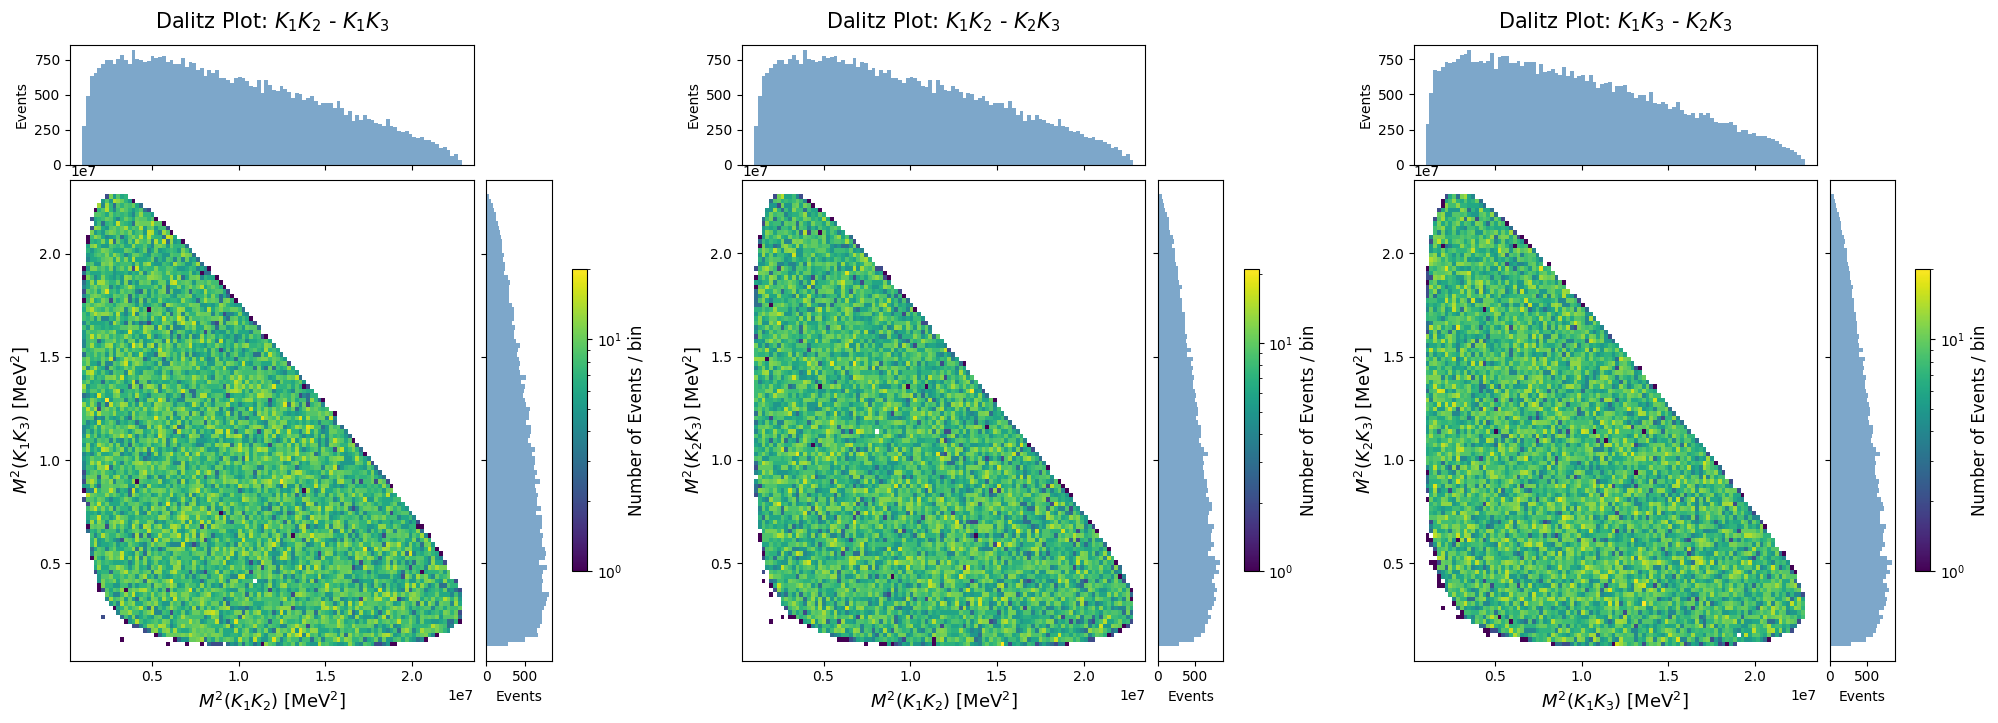

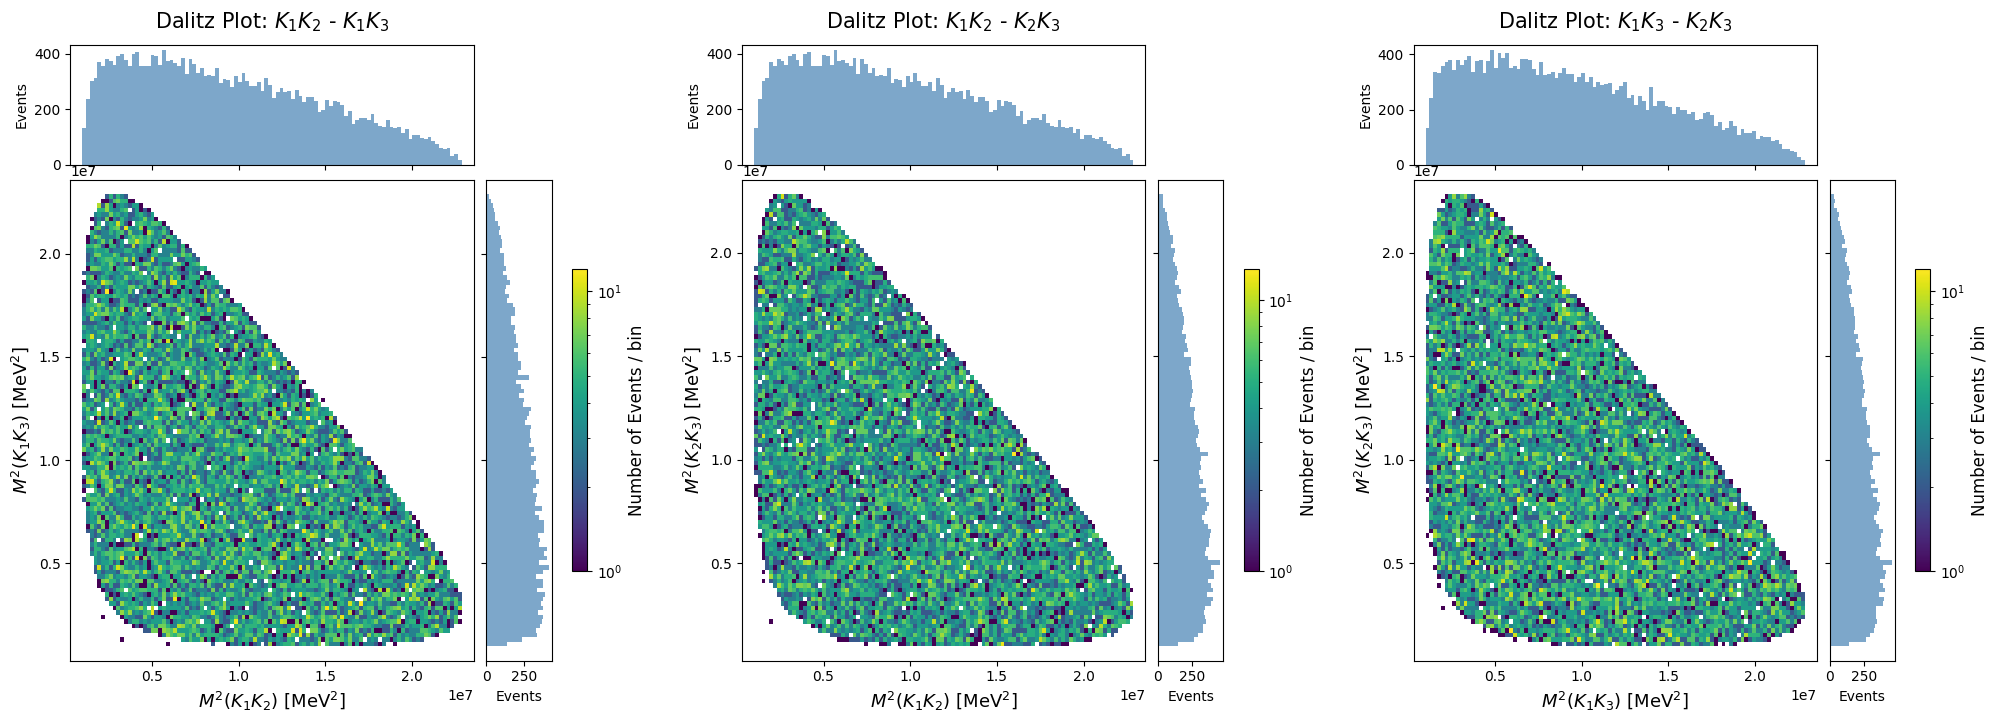

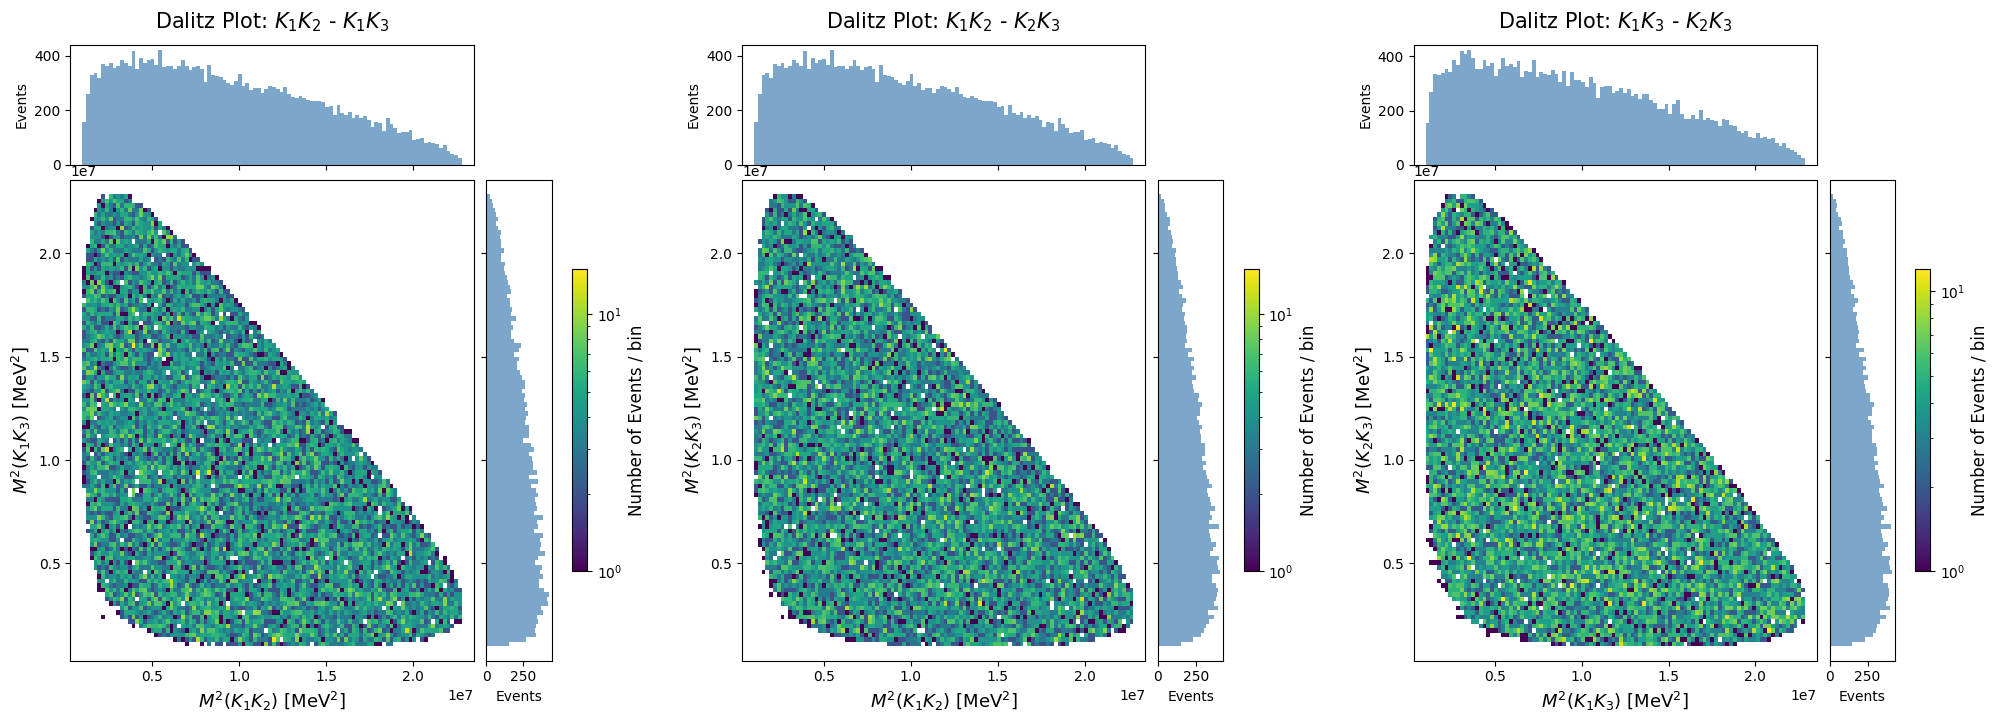

In [34]:
df_sim_charge_split = lf.split_by_charge(df_sim, col=df_sim.columns)
fig = lf.dalitz_plot(cfg, data=df_sim,                     bins=100)
fig = lf.dalitz_plot(cfg, data=df_sim_charge_split['pos'], bins=100)
fig = lf.dalitz_plot(cfg, data=df_sim_charge_split['neg'], bins=100)

### Real Data

In [ ]:
# For Real Data the charge of 2 and 3 is the same (also equal to B charge)
#    --> 12 = 0
#    --> 13 = 0
#    --> 23 = ++/-- (should be no peak of M_23 in the Dalitz Plot) --> OK!

data[['H1_Charge', 'H2_Charge', 'H3_Charge', 'B_Charge']][:5]

,H1_Charge,H2_Charge,H3_Charge,B_Charge
0,-1,1,1,1
1,1,-1,-1,-1
2,-1,1,1,1
3,-1,1,1,1
4,1,-1,-1,-1


In [ ]:
# # apply a cut on the B mass values (signal) to reduce the bkg
# data_signal = lf.select_window(data, cfg.sig_region)
# data_signal = data
# # plt.hist(data_signal['B_Mass'], bins=100);

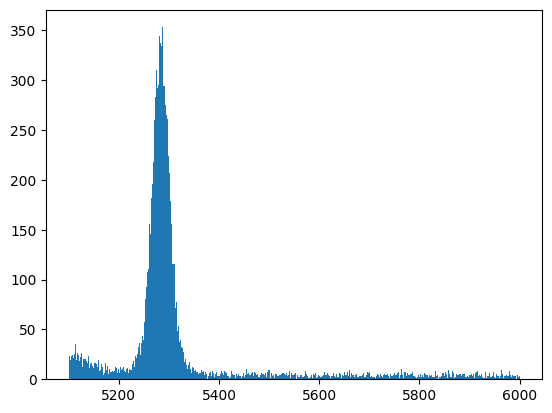

In [357]:
plt.hist(data_window['B_Mass'], bins=1000);

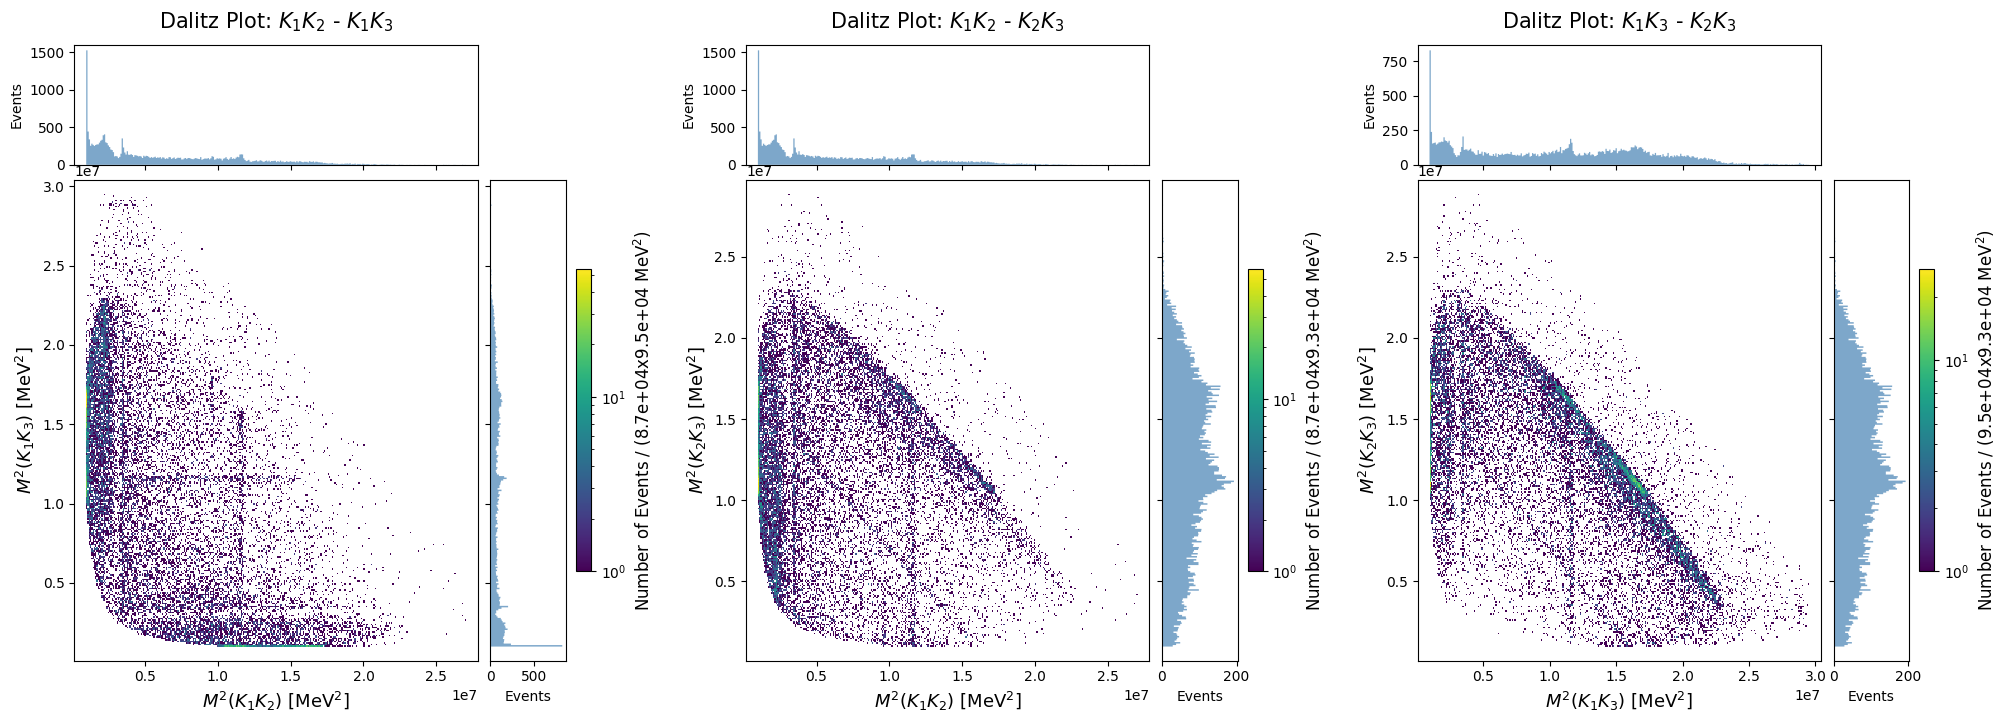

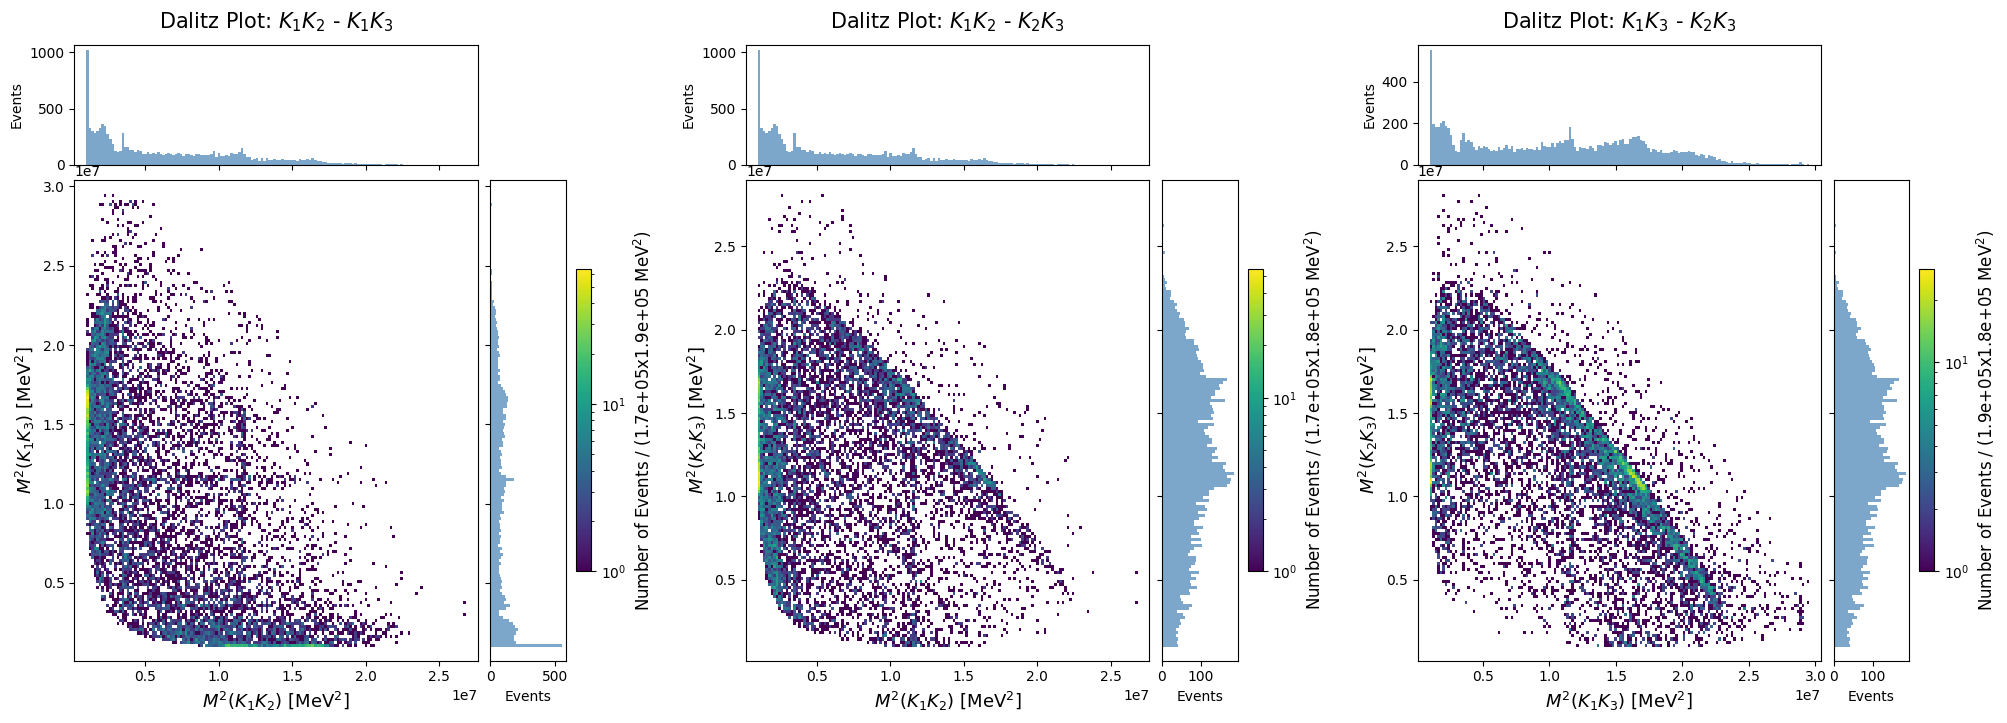

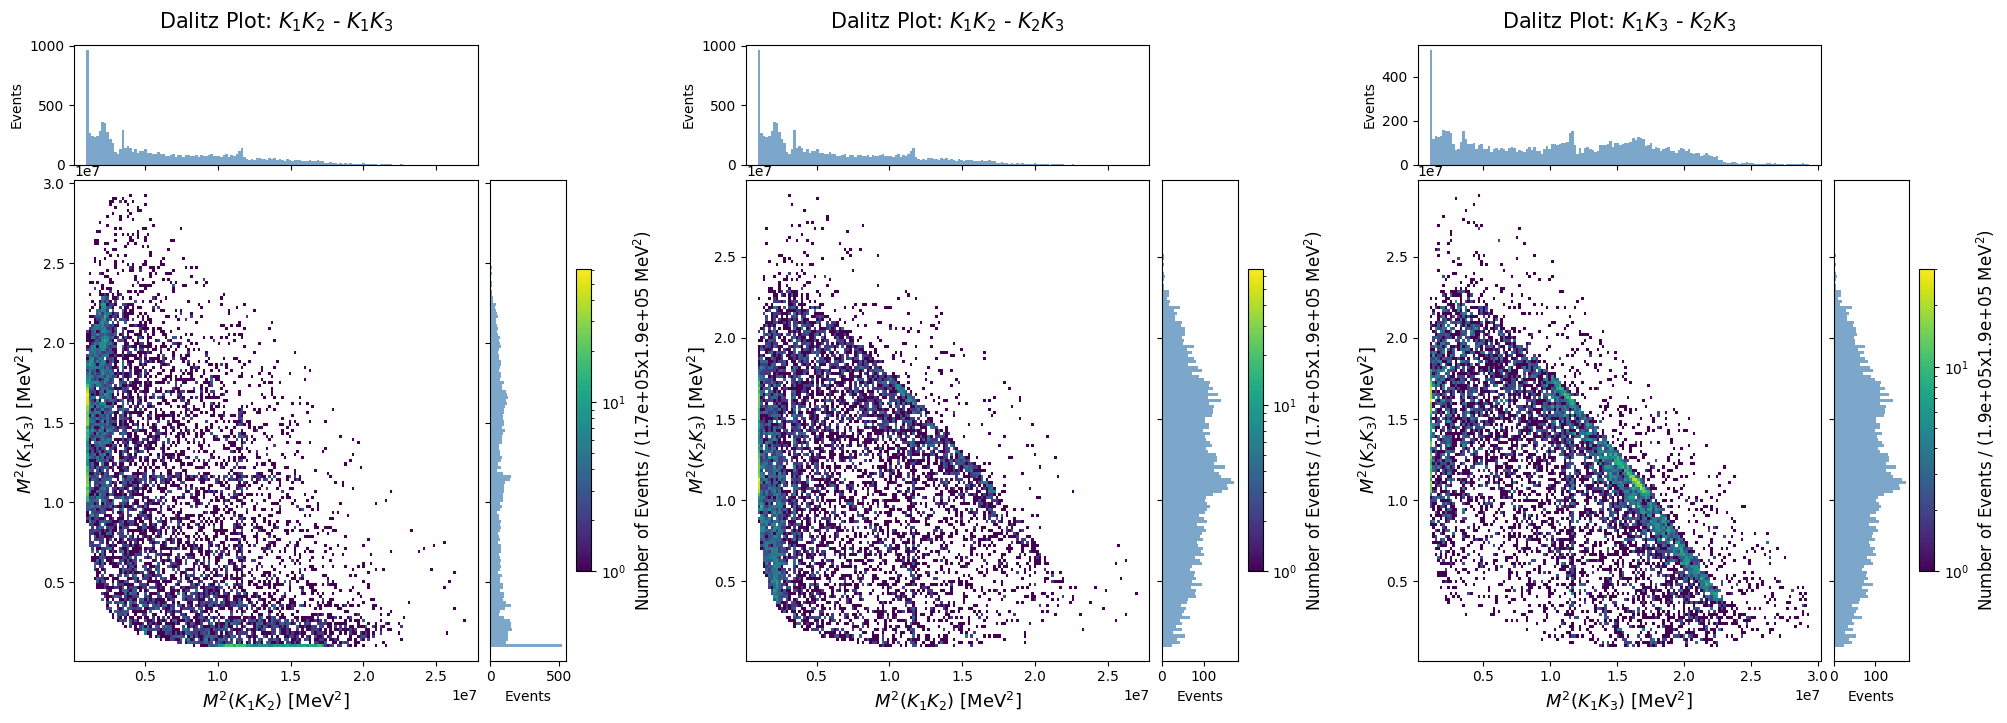

In [358]:
data_charge_split = lf.split_by_charge(data_window, col=data.columns)
fig, *_ = lf.dalitz_plot(cfg, data=data_window,              bins=300)
fig, *_ = lf.dalitz_plot(cfg, data=data_charge_split['pos'], bins=150)
fig, *_ = lf.dalitz_plot(cfg, data=data_charge_split['neg'], bins=150)

B charge:  pos
   Mass:  1865.475810617763 MeV
   Mass:  3398.529093593286 MeV
B charge:  neg
   Mass:  1865.475810617763 MeV
   Mass:  3398.529093593286 MeV


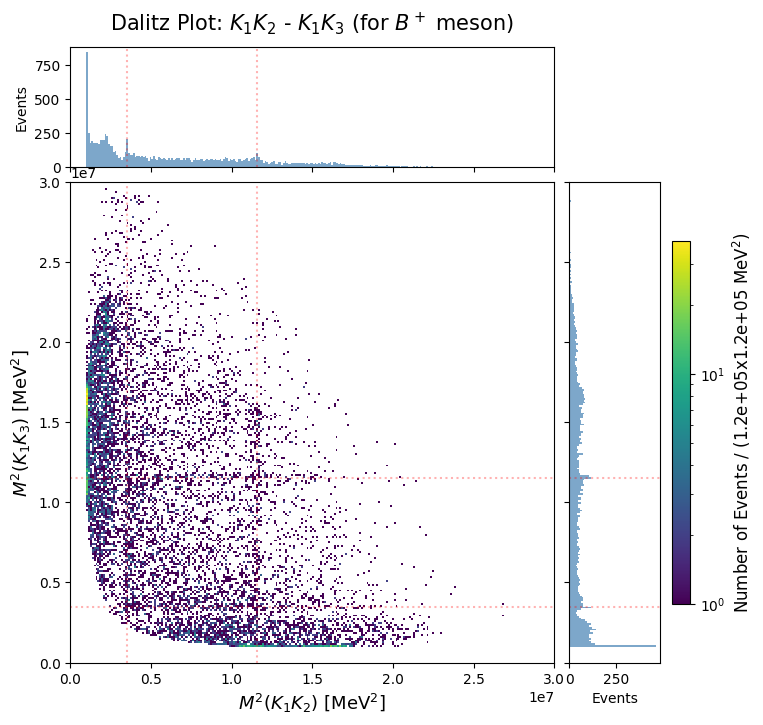

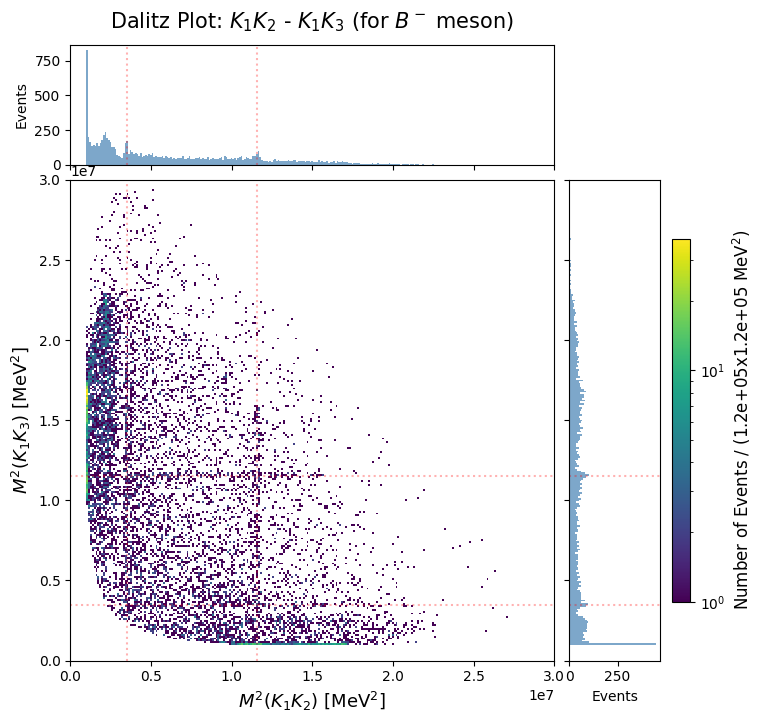

In [360]:
for charge, data_split in data_charge_split.items():
    print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *_ = lf.dalitz_plot(cfg, mass=interesting_mass, bins=250, range=[[0,3e7],[0,3e7]],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')

    possible_peaks = [0.348e7, 1.155e7]
    for possible_peak in possible_peaks:
        ax.axvline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        ax.axhline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        ax_top.axvline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        ax_left.axhline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        print("   Mass: ", np.sqrt(possible_peak), "MeV")

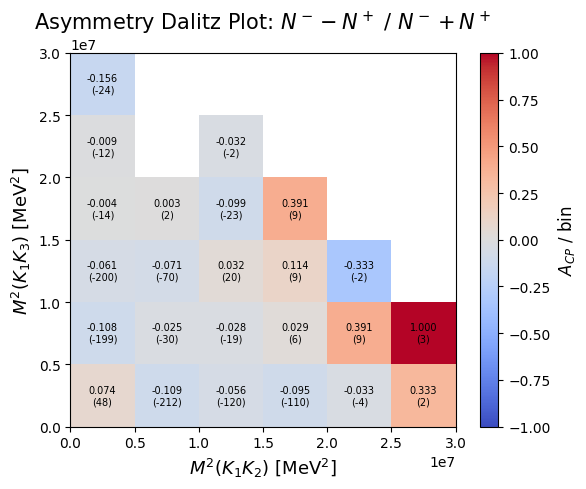

C:\Users\marco\AppData\Local\Temp\ipykernel_25344\4121470509.py:61: RuntimeWarning: divide by zero encountered in divide
  histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))
C:\Users\marco\AppData\Local\Temp\ipykernel_25344\4121470509.py:61: RuntimeWarning: invalid value encountered in divide
  histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))
C:\Users\marco\AppData\Local\Temp\ipykernel_25344\4121470509.py:73: RuntimeWarning: invalid value encountered in scalar divide
  val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])
C:\Users\marco\AppData\Local\Temp\ipykernel_25344\4121470509.py:73: RuntimeWarning: divide by zero encountered in scalar divide
  val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])


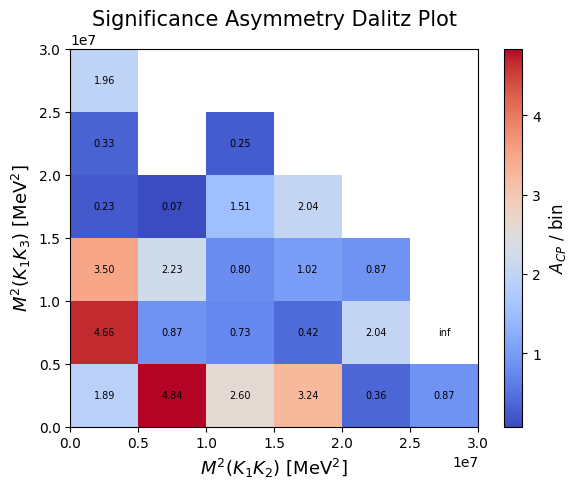

In [375]:
bins_histo_asymm=6

histo = {}
for charge, data_split in data_charge_split.items():
    # print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *histo[charge] = lf.dalitz_plot(cfg, mass=interesting_mass, bins=bins_histo_asymm, range=[[0,3e7],[0,3e7]],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')
    plt.close()


x_centers = np.array((histo['neg'][1][:-1] + histo['neg'][1][1:]) / 2)
y_centers = np.array((histo['neg'][2][:-1] + histo['neg'][2][1:]) / 2)

with np.errstate(divide='ignore', invalid='ignore'):
    histo_diff = histo['neg'][0] - histo['pos'][0]
    histo_A_CP, histo_err_A_CP = lf.raw_asymmetry(histo['pos'][0], histo['neg'][0])
    histo_A_CP = np.nan_to_num(histo_A_CP, nan=0.0)
    histo_err_A_CP = np.nan_to_num(histo_err_A_CP, nan=0.0)

histo_A_CP_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, histo_A_CP)
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_A_CP_masked.T,
    cmap='coolwarm', 
    norm=CenteredNorm(vcenter=0)
)
for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = histo_A_CP[i, j]
        err_val2 = histo_err_A_CP[i, j]
        
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.3f}\n({int(val1)})",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Asymmetry Dalitz Plot: $N^- - N^+$ / $N^- + N^+$", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

# -----------------------------------------------------------------------------------------------------------

histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_significance_masked.T, 
    cmap='coolwarm', 
    # norm=CenteredNorm(vcenter=0)
)

for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.2f}",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Significance Asymmetry Dalitz Plot", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

### Ordering Dalitz variables
You can make a further improvement to allow you to observe the resonances easier. Your resonances R<sup>0</sup><sub>2</sub> and R<sup>0</sup><sub>3</sub> are both composed of the same particle types, K<sup>+</sup>K<sup>-</sup>, and hence have the same distributions. It is useful to impose an ordering which distinguishes the resonances. We can call the resonances R<sup>0</sup><sub>Low</sub> and R<sup>0</sup><sub>High</sub>. In each event R<sup>0</sup><sub>Low</sub> is the resonance with the lower mass and the other corresponds to the higher mass combination of kaons. You can now use the mass of these ordered resonances as your Dalitz plot variables, thus effectively "folding" your Dalitz plot so that one axis always has a higher value than the other.


In [362]:
# make a new Dalitz plot with a mass ordering of the axes

### Hint

**Ordered Dalitz plot** - You can find the maximum of the mass of R<sup>0</sup><sub>Low</sub> vs R<sup>0</sup><sub>High</sub> elementwise on one axis, and the minimum of on the other. You can use `numpy.min(a,b)` and `numpy.max(a,b)` to perform elementwise comparisons between two arrays `a` and `b` and return one array filled by either the individual min/max element from the elementwise comparisons.

## Observing CP violation

From your studies of the asymmetry plot, and the plot of its significance, you will be able to identify regions in the Dalitz plots that show indications of sizeable and significant CP Violation. You may find you have several consecutive bins with significant positive, or negative, asymmetries. You may wish to try alternative binnings of the Dalitz plots to best isolate the regions in which the significant asymmetries occur.

You can select events that are in these regions of the Dalitz plots where you observe signs of CP Violation. You can then plot a simple 1D histogram of the invariant mass distribution of the B<sup>+</sup> and the B<sup>-</sup> events, just as you did at the start of the project, but only for events that lie in the region of the Dalitz plot that you are interested in. Make the plots of the B<sup>+</sup> and the B<sup>-</sup> events with the same scale, or superimpose the two plots, so that you can observe if the particle and anti-particle decay processes are occurring at the same rate.

In [363]:
# Make a plot showing the invariant mass of the B+ meson particles
# using events from a region of the Dalitz plot showing sizeable CP asymmetries

In [371]:
# Make a plot showing the invariant mass of the B- meson particles using events from the same region

## Removing charm resonances

The analysis performed here is to study the CP violation in the charmless B meson decays to kaons. "charmless" means that the decay does not proceed through a charm quark. However, the most frequent decay of the B mesons occur through the *b* quark decaying into a *c* quark. The majority of these events can be removed by rejecting the events that are proceeding through a D<sup>0</sup> meson (which contains the charm quark).

In the section above you plotted a histogram of the invariant mass of the intermediate resonances and will have observed the D<sup>0</sup> meson in this and in the Dalitz plot. You should now reject events that are around the mass range of the D<sup>0</sup> meson to suppress this contribution. You can do this in your pre-selection on the data that you set-up earlier in the project.

This was also a simplification that we did not consider when we were calculating the global asymmetry. After you have applied this pre-selection your code will now recompute the global asymmetry with the D<sup>0</sup> meson contribution rejected. We have not yet observed CP violation in charm mesons and searching for this is another active area of current research.

# Further analyses

The data set you have been provided is the full set of data recorded by LHCb preselected for decays of charged B mesons into three final state tracks. This data set has been used for two important publications, [here](http://lhcbproject.web.cern.ch/lhcbproject/Publications/LHCbProjectPublic/LHCb-PAPER-2013-027.html) and [here](http://lhcbproject.web.cern.ch/lhcbproject/Publications/LHCbProjectPublic/LHCb-PAPER-2013-051.html).

We discuss here: 
<ul>
<li>Additional elements that you could add to your analysis of B<sup>+</sup> → K<sup>+</sup>K<sup>+</sup>K<sup>−</sup> </li>
<li>Further analyses that you could perform with this data set</li>
</ul>

## Adding extra sophistication

### Systematic Uncertainties
In this analysis you considered the statistical uncertainty on the result. This occurs as a result of having only a limited number of events. In addition there are [systematic uncertainties](https://en.wikipedia.org/wiki/Observational_error#Systematic_versus_random_error), these arise from biases in your measurement. Here we discuss three sources of these for this analysis.
<ul>
<li> Production asymmetry. The LHC is a proton-proton collider and hence the initial state of the collision is not matter antimatter symmetric. Consequently B<sup>+</sup> and B<sup>-</sup> mesons may not be produced at exactly the same rates. This small production asymmetry it is estimated could be approximately 1%. It can also be measured from the data, as discussed in the LHCb paper.</li>
<li> Detection asymmetry. The LHCb detector could be more efficient for detecting either the B<sup>+</sup> or the B<sup>-</sup> final states. This is because the positive and negative kaons will be bent by the magnet indifferent directions in the detector. If the efficiency of the detector is higher in one region than another this will lead to higher efficiencies for K<sup>+</sup> or K<sup>-</sup> and hence for B<sup>+</sup> or B<sup>-</sup>. For this reason the magnetic field of the LHCb detector is regularly reversed. You used data in this analysis in which the magnetic field was both up and down and hence the effect will (partially) cancel. By comparing results for the two magnet polarities separately you can check the size of this effect. When loading the data above both polarities were combined, you can instead load them independently to measure the difference between the two datasets.</li>
<li> Analysis technique. The analysis technique you have used may bias the result. A major simplification we made in the analysis above was to neglect 'background' events. We imposed a selection to select a sample of predominantly signal events but have not accounted for the effect of the residual background events.</li>
</ul>

### Using mass sidebands

One source of 'background' events arises from random combinations of tracks in events that happen to fake the 'signal' characteristics. These events will not peak in the mass distribution at the mass of the B meson but rtaher will have a smoothly varying distribution. Looking at the number and distribution of of events away from the mass peak can allow you to estimate the number of background events under the mass peak.

### Fitting distributions

The next level of sophistication in the analysis requires fitting the distributions of events that are observed in the B mass distribution in order to estimate the yield of signal events and background events. You can see how this is done in the LHCb paper on the analysis. Fitting can be performed using the [CERN root framework](https://root.cern.ch/).

## Further analyses

The LHCb papers using this data set that you are using analysed four decay channels of the charged B mesons. You can perform any of these analyses.
<ul>
<li>B<sup>+</sup> → K<sup>+</sup>K<sup>+</sup>K<sup>−</sup> (and anti-particle equivalent). This is the analysis you have performed here. It has the lowest background of the four channels and hence the approximation we made of neglecting the background events will give the least bias to this channel.</li>
<li>B<sup>+</sup> → &pi;<sup>+</sup>&pi;<sup>+</sup>&pi;<sup>−</sup> (and anti-particle equivalent). In this analysis the final state is three charged pions. The level of background events compared to the signal is significantly higher as pions are the most commonly produced particle at the LHC. Hence, a method of estimating the background level should be added to complete this analysis.</li>
<li>B<sup>+</sup> → K<sup>+</sup>&pi;<sup>+</sup>&pi;<sup>−</sup> (and anti-particle equivalent). In this analysis the final state is a mixture of one kaon and two pions. This means that the analysis needs to determine in each event which track is the best candidate kaon and apply selection cuts appropriately to select out the events.</li>
<li>B<sup>+</sup> → &pi;<sup>+</sup>K<sup>+</sup>K<sup>−</sup> (and anti-particle equivalent). This channel has a higher level of background compared to the signal.</li>
</ul>

## TODO (branch `freq`, responsabile: Marco)

1. Eseguire tutte le celle sopra end-to-end (baseline): lettura simulazione, massa invariante, dati reali, preselezione, {raw}$ globale da conteggio, Dalitz plot.
2. Costruire il modello di massa signal + background con **iminuit** (`iminuit.cost.UnbinnedNLL`): (m) = N_s\,S(m;	heta_s) + N_b\,B(m;	heta_b)$.
3. Fit separato (^+$/^-$) e fit simultaneo parametrizzato su $.
4. Profile likelihood (A)$ e confidence interval (Wilks); test =0$.

Vedi `Docs/Proposta_progetto_LHCb_gruppo.tex`, sezioni "Estensione frequentista" e "Pipeline operativa proposta".